# STAT 8100 — Biostatistics and Epidemiology Practical Companion

**STAT 8100 · Lectures 1–6 · simulated teaching datasets**

This notebook is a complete, executable navigation guide for Questions 1–10. Run the reusable setup first, then work through the questions in order. Every code cell has been executed against the three CSV files in this folder; its output is preserved below the cell.

## How to use this notebook

- Run **Reusable setup** once before any question code cell. Question cells reuse `anc`, `record()` and the other objects created there; running one alone now gives a clear prerequisite error.
- Run **Dataset audit** once to reproduce the verification recorded below.
- For each question, read the learning guide, run the listed code cell(s), inspect the output, then write your own interpretation and report.
- The `mark_done` cell at the end of each question updates the progress indicator.
- Each reporting template is shown twice: once as a reusable sentence frame and once as a worked example filled from the executed notebook.

## Navigation

| Question | Topic |
| --- | --- |
| Q1 | Probability and probability distributions |
| Q2 | Descriptive statistics and correlation |
| Q3 | Estimation and confidence intervals |
| Q4 | Comparing mean birthweight by IPTp3 status |
| Q5 | Paired t-test for blood pressure |
| Q6 | ANOVA and non-parametric comparison |
| Q7 | Categorical data and proportions |
| Q8 | Linear regression |
| Q9 | Logistic regression |
| Q10 | Survival analysis |

A searchable HTML version with expandable cards and copy-code buttons is available as `stat8100_practical_companion.html` in the same folder.


## Dataset audit — completed before implementation

| Verification | Finding |
| --- | --- |
| All three CSVs load successfully. | anc_cohort.csv is 400×14, bp_paired.csv is 60×3 and postpartum_survival.csv is 500×6. |
| Required columns are present. | No expected analysis variable is absent. bp_paired.csv also contains an id column, which is useful for confirming the pairing. |
| Missingness is variable-specific. | ANC: bmi 10, hb 18, anaemia 18; all other ANC variables have zero missing values. BP and survival datasets have no missing values. |
| Education uses a literal category name. | The 55 'None' values are a real education level, not missing data. The loader uses keep_default_na=False so pandas does not silently convert them to NaN. |
| Binary coding is consistent. | iptp3 uses Yes/No; preterm, low_bw and readmitted use 1/0 with the meanings stated in the practical. |
| Anaemia and low birth weight are internally consistent. | (hb < 11) matches anaemia for all 382 evaluable records; (birthweight < 2500) matches low_bw for all 400 records. |
| Preterm has a documented definition discrepancy. | Nine records have gest_age between 36.1 and 36.8 weeks but preterm = 0. The supplied preterm flag is used as the primary outcome; interpret it as the recorded clinical flag, not an exact recoding of decimal gest_age. |
| No duplicate identifiers or duplicate rows were found. | ANC ids W001–W400, BP ids B01–B60 and survival ids P001–P500 are unique. |
| Outliers are plausible and retained. | Gestational age has a left tail, birthweight has a few low/high IQR outliers and BP has a few extreme measurements. They are inspected, not deleted. |
| These are simulated teaching data. | They are not real patient records and must not be used for clinical or public-health decisions. |

### Source fingerprints (SHA-256, LF-normalised files)

| File | SHA-256 |
| --- | --- |
| anc_cohort.csv | EE9D58D5E484D62244B62E17910AEDE241B074B4E7F70D22C783F50DD6E9E1DA |
| bp_paired.csv | 677B7643994C0C57CE9FA2C052EEB22086D5B20537E5D8FE1290A98B3AFEF786 |
| postpartum_survival.csv | 0099FFCFCC226141DD762E6ABD338343325DC360A8011FFC571CAB06AC332EF2 |

The supplied Google Drive files and the bundled `frontend/resources/samples` copies have identical LF-normalised content; the deployed sample files now use the Drive bytes.


## Reusable setup

In [1]:
# Reusable setup — run this once before any question.
from pathlib import Path
import json
import math
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import (
    proportion_confint,
    proportions_ztest,
    confint_proportions_2indep,
)
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests
from statsmodels.duration.survfunc import SurvfuncRight
from statsmodels.duration.hazard_regression import PHReg

# Matplotlib's inline backend is the Jupyter default; no IPython-only magic
# is needed, so this cell also parses and runs under plain Python.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 130)
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_FILES = {
    "anc": "anc_cohort.csv",
    "bp": "bp_paired.csv",
    "survival": "postpartum_survival.csv",
}
NUMERIC_COLUMNS = {
    "anc": ["age", "parity", "bmi", "anc_visits", "hb", "anaemia",
            "preterm", "gest_age", "birthweight", "low_bw"],
    "bp": ["sbp_booking", "sbp_36wk"],
    "survival": ["time_days", "readmitted", "age"],
}
QUESTION_IDS = [f"Q{i}" for i in range(1, 11)]


def find_data_dir():
    """Find the uploaded CSVs from a notebook opened in several locations."""
    candidates = []
    env_dir = os.environ.get("MNH_DATA_DIR")
    if env_dir:
        candidates.append(Path(env_dir).expanduser().resolve())
    here = Path.cwd().resolve()
    for _ in range(7):
        candidates.extend([
            here / "frontend" / "resources" / "samples",
            here / "resources" / "samples",
            here / "samples",
            here,
        ])
        here = here.parent
    for candidate in candidates:
        if candidate.is_dir() and all((candidate / name).is_file()
                                      for name in DATA_FILES.values()):
            return candidate
    raise FileNotFoundError(
        "Could not find anc_cohort.csv, bp_paired.csv and "
        "postpartum_survival.csv. Set MNH_DATA_DIR to their folder."
    )


def load_csv(key):
    """Read a CSV while preserving the literal education level 'None'."""
    path = DATA_DIR / DATA_FILES[key]
    frame = pd.read_csv(
        path,
        keep_default_na=False,
        na_values=["", "NA", "N/A", "NaN", "nan", "null", "NULL"],
    )
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        frame[column] = frame[column].str.strip()
    for column in NUMERIC_COLUMNS[key]:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


DATA_DIR = find_data_dir()
anc = load_csv("anc")
bp = load_csv("bp")
surv = load_csv("survival")

RESULTS = {}
PROGRESS = set()


def _clean_nan(value):
    if isinstance(value, float) and math.isnan(value):
        return None
    return value


def jsonable(obj):
    """Convert pandas/numpy results into JSON-safe plain Python values."""
    if obj is pd.NA or obj is pd.NaT:
        return None
    if isinstance(obj, dict):
        return {str(k): jsonable(_clean_nan(v)) for k, v in obj.items()}
    if isinstance(obj, (set, frozenset)):
        return [jsonable(_clean_nan(v)) for v in sorted(obj, key=repr)]
    if isinstance(obj, (list, tuple)):
        return [jsonable(_clean_nan(v)) for v in obj]
    if isinstance(obj, pd.DataFrame):
        return jsonable(obj.to_dict(orient="records"))
    if isinstance(obj, pd.Series):
        return jsonable(obj.to_dict())
    if isinstance(obj, np.ndarray):
        return jsonable(obj.tolist())
    if isinstance(obj, np.generic):
        return jsonable(obj.item())
    if isinstance(obj, complex):
        raise ValueError("Complex results are not JSON-serialisable.")
    return _clean_nan(obj)


def record(key, value):
    """Store a verified result for the companion's output panel."""
    RESULTS[key] = jsonable(value)
    return RESULTS[key]


def show_progress():
    bar = "".join("■" if q in PROGRESS else "□" for q in QUESTION_IDS)
    done = sum(q in PROGRESS for q in QUESTION_IDS)
    print(f"Progress: {bar}  {done}/10 questions covered")


def mark_done(question_id):
    PROGRESS.add(question_id)
    show_progress()


print("DATA_DIR:", DATA_DIR)
print("Simulated teaching datasets loaded:",
      f"anc={anc.shape}, bp={bp.shape}, survival={surv.shape}")
show_progress()


DATA_DIR: C:\Users\AMINILOGY\Documents\Default Project\MNH-Smart-Calendar-v13\frontend\resources\samples
Simulated teaching datasets loaded: anc=(400, 14), bp=(60, 3), survival=(500, 6)
Progress: □□□□□□□□□□  0/10 questions covered


## Dataset audit code

In [2]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

import hashlib

audit_rows = []
for key, name in DATA_FILES.items():
    path = DATA_DIR / name
    frame = {"anc": anc, "bp": bp, "survival": surv}[key]
    audit_rows.append({
        "dataset": name,
        "rows": int(frame.shape[0]),
        "columns": int(frame.shape[1]),
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest().upper(),
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
    })
audit_table = pd.DataFrame(audit_rows)
print(audit_table.to_string(index=False))
print("\nANC column order:", list(anc.columns))
print("BP column order:", list(bp.columns))
print("Survival column order:", list(surv.columns))
print("\nANC missingness:")
print(anc.isna().sum().to_string())
print("\nEducation levels:", anc["education"].value_counts(dropna=False).to_dict())
print("IPTp3 levels:", anc["iptp3"].value_counts(dropna=False).to_dict())
print("Facility levels:", anc["facility_type"].value_counts(dropna=False).to_dict())

anaemia_check = (anc["hb"] < 11).astype("Int64") == anc["anaemia"].astype("Int64")
preterm_check = (anc["gest_age"] < 37).astype("Int64") == anc["preterm"].astype("Int64")
lowbw_check = (anc["birthweight"] < 2500).astype("Int64") == anc["low_bw"].astype("Int64")
print("\nDerived-variable checks (mismatches among evaluable rows):")
print("  anaemia vs hb<11:", int((~anaemia_check.dropna()).sum()),
      "evaluable:", int(anaemia_check.notna().sum()))
print("  preterm vs gest_age<37:", int((~preterm_check.dropna()).sum()),
      "evaluable:", int(preterm_check.notna().sum()))
print("  low_bw vs birthweight<2500:", int((~lowbw_check.dropna()).sum()),
      "evaluable:", int(lowbw_check.notna().sum()))
record("Audit", {
    "datasets": audit_table.to_dict(orient="records"),
    "education_levels": anc["education"].value_counts(dropna=False).to_dict(),
    "facility_levels": anc["facility_type"].value_counts(dropna=False).to_dict(),
    "iptp3_levels": anc["iptp3"].value_counts(dropna=False).to_dict(),
    "anaemia_mismatches": int((~anaemia_check.dropna()).sum()),
    "preterm_mismatches": int((~preterm_check.dropna()).sum()),
    "lowbw_mismatches": int((~lowbw_check.dropna()).sum()),
})


                dataset  rows  columns                                                           sha256  missing_cells  duplicate_rows
         anc_cohort.csv   400       14 EE9D58D5E484D62244B62E17910AEDE241B074B4E7F70D22C783F50DD6E9E1DA             46               0
          bp_paired.csv    60        3 677B7643994C0C57CE9FA2C052EEB22086D5B20537E5D8FE1290A98B3AFEF786              0               0
postpartum_survival.csv   500        6 0099FFCFCC226141DD762E6ABD338343325DC360A8011FFC571CAB06AC332EF2              0               0

ANC column order: ['id', 'facility_type', 'age', 'parity', 'education', 'bmi', 'anc_visits', 'iptp3', 'hb', 'anaemia', 'preterm', 'gest_age', 'birthweight', 'low_bw']
BP column order: ['id', 'sbp_booking', 'sbp_36wk']
Survival column order: ['id', 'time_days', 'readmitted', 'anaemia', 'delivery_mode', 'age']

ANC missingness:
id                0
facility_type     0
age               0
parity            0
education         0
bmi              10
anc_visits 

{'datasets': [{'dataset': 'anc_cohort.csv',
   'rows': 400,
   'columns': 14,
   'sha256': 'EE9D58D5E484D62244B62E17910AEDE241B074B4E7F70D22C783F50DD6E9E1DA',
   'missing_cells': 46,
   'duplicate_rows': 0},
  {'dataset': 'bp_paired.csv',
   'rows': 60,
   'columns': 3,
   'sha256': '677B7643994C0C57CE9FA2C052EEB22086D5B20537E5D8FE1290A98B3AFEF786',
   'missing_cells': 0,
   'duplicate_rows': 0},
  {'dataset': 'postpartum_survival.csv',
   'rows': 500,
   'columns': 6,
   'sha256': '0099FFCFCC226141DD762E6ABD338343325DC360A8011FFC571CAB06AC332EF2',
   'missing_cells': 0,
   'duplicate_rows': 0}],
 'education_levels': {'Primary': 212, 'Secondary+': 133, 'None': 55},
 'facility_levels': {'Urban': 154, 'Peri-urban': 133, 'Rural': 113},
 'iptp3_levels': {'Yes': 243, 'No': 157},
 'anaemia_mismatches': 0,
 'preterm_mismatches': 9,
 'lowbw_mismatches': 0}

<a id="q1"></a>

## Q1. Probability and probability distributions

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q1a | Estimate P(preterm) and P(low birth weight) from anc_cohort.csv. | Calculation | Run the Q1(a) cell and read the counts, denominators and sample proportions. | See code cell q1a | Event counts, denominator 400 and the two sample proportions. | Treat each proportion as an estimate with sampling variability; only a confidence interval quantifies that variability. | Report 'In the simulated ANC cohort, 47/400 (0.1175) were preterm and 43/400 (0.1075) had low birth weight.' |
| Q1b | Estimate P(low birth weight \| preterm) and P(low birth weight \| term), then assess independence. | Mixed | Run Q1(b), inspect the conditional proportions and compare them with the marginal probability. | See code cell q1b | Conditional proportions across the two preterm strata and the risk difference/ratio. | If the conditional probabilities differ materially from each other and from the marginal probability, the events are not independent in this sample. | Report each conditional probability and say whether they are close, with the observed risk difference. |


#### Q1a — Estimate marginal probabilities

**Practical requirement.** Estimate P(preterm) and P(low birth weight) from anc_cohort.csv.
**Task classification.** Calculation
**Code required.** Yes

**Learning guide**

- What is being asked? Estimate two unconditional probabilities using the supplied outcome flags.
- Statistical concept: A sample proportion estimates a population probability; it is not a theoretical probability.
- Do you need to write code? Yes — one short calculation cell.
- What to do in Jupyter: Run Q1(a), then compare the counts with the denominators.
- Code to use: Use the verified Q1(a) code cell.
- Output to inspect: A table with event count, denominator and sample proportion for each outcome.
- Important values or observations: 47/400 preterm and 43/400 low birth weight in the actual file.
- How to interpret it: These are observed sample proportions from simulated teaching data, not known population truths.
- What to report: State the numerator, denominator and resulting proportion for each event.
- Common mistakes to avoid: Do not use 382 as the denominator here; preterm and low_bw are complete for all 400 records.

**Output to inspect.** Event counts, denominator 400 and the two sample proportions.

**Interpretation guidance.** Treat each proportion as an estimate with sampling variability; only a confidence interval quantifies that variability.

**Reporting guidance.** Report 'In the simulated ANC cohort, 47/400 (0.1175) were preterm and 43/400 (0.1075) had low birth weight.'

**Worked report from the executed notebook.** In the simulated ANC cohort (n=400), 47/400 (0.1175) preterm delivery and 43/400 (0.1075) low birth weight. These are observed sample proportions from the recorded outcome flags, not known population probabilities.

*Verified source:* Q1a output · anc_cohort.csv. *Teaching note:* Both outcome flags are complete for every record here. Do not switch to the smaller anaemia denominator used later.

**Common mistakes.** Confusing sample proportion with theoretical probability, or silently changing the denominator.


**Code cell `q1a`**

In [3]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

n_preterm = int(anc["preterm"].notna().sum())
n_lowbw = int(anc["low_bw"].notna().sum())
p_preterm = float(anc["preterm"].mean())
p_lowbw = float(anc["low_bw"].mean())
q1a_table = pd.DataFrame({
    "event": ["Preterm delivery", "Low birth weight"],
    "count": [int(anc["preterm"].sum()), int(anc["low_bw"].sum())],
    "denominator": [n_preterm, n_lowbw],
    "sample_proportion": [p_preterm, p_lowbw],
})
print(q1a_table.to_string(index=False, formatters={
    "sample_proportion": lambda v: f"{v:.4f}"
}))
record("Q1a", q1a_table.to_dict(orient="records"))


           event  count  denominator sample_proportion
Preterm delivery     47          400            0.1175
Low birth weight     43          400            0.1075


[{'event': 'Preterm delivery',
  'count': 47,
  'denominator': 400,
  'sample_proportion': 0.1175},
 {'event': 'Low birth weight',
  'count': 43,
  'denominator': 400,
  'sample_proportion': 0.1075}]

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q1b — Conditional probability and independence

**Practical requirement.** Estimate P(low birth weight | preterm) and P(low birth weight | term), then assess independence.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Compare low-birth-weight risk in preterm and term babies and judge whether the events look independent.
- Statistical concept: Conditional probability restricts the denominator to a stratum; independence requires the conditional probability to equal the marginal probability.
- Do you need to write code? Yes — one calculation cell.
- What to do in Jupyter: Run Q1(b), then read the contingency table and conditional proportions.
- Code to use: Use the verified Q1(b) code cell.
- Output to inspect: Stratum counts, denominators, conditional probabilities, risk difference and risk ratio.
- Important values or observations: P(low_bw | preterm) versus P(low_bw | term) and the marginal P(low_bw).
- How to interpret it: Large differences suggest dependence; similar values are consistent with independence but do not prove it.
- What to report: Report both conditional probabilities and describe the direction and size of the difference.
- Common mistakes to avoid: Never declare independence solely because a test is non-significant, and never infer causation.

**Output to inspect.** Conditional proportions across the two preterm strata and the risk difference/ratio.

**Interpretation guidance.** If the conditional probabilities differ materially from each other and from the marginal probability, the events are not independent in this sample.

**Reporting guidance.** Report each conditional probability and say whether they are close, with the observed risk difference.

**Worked report from the executed notebook.** Low birth weight occurred in 14/47 (0.2979) preterm and 29/353 (0.0822) term births, compared with the marginal 43/400 = 0.1075. The risk difference is 0.2157 and the risk ratio is 3.63, so the events are not independent in these simulated data.

*Verified source:* Q1a and Q1b outputs · anc_cohort.csv. *Teaching note:* Compare conditional with marginal proportions. Similarity in a sample is not proof of independence, and dependence is not causation.

**Common mistakes.** Using the wrong denominator, or treating similarity as proof of independence.


**Code cell `q1b`**

In [4]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

preterm_group = anc.loc[anc["preterm"] == 1, "low_bw"]
term_group = anc.loc[anc["preterm"] == 0, "low_bw"]
p_lb_given_preterm = float(preterm_group.mean())
p_lb_given_term = float(term_group.mean())
q1b_table = pd.DataFrame({
    "stratum": ["Preterm (preterm=1)", "Term (preterm=0)"],
    "low_bw_count": [int(preterm_group.sum()), int(term_group.sum())],
    "stratum_n": [int(preterm_group.size), int(term_group.size)],
    "P(low_bw | stratum)": [p_lb_given_preterm, p_lb_given_term],
})
contingency_q1 = pd.crosstab(anc["preterm"], anc["low_bw"], margins=True)
print(q1b_table.to_string(index=False, formatters={
    "P(low_bw | stratum)": lambda v: f"{v:.4f}"
}))
print("\nContingency table (rows=preterm, columns=low_bw):")
print(contingency_q1.to_string())
print(f"\nRisk difference = {p_lb_given_preterm - p_lb_given_term:+.4f}")
print(f"Risk ratio = {p_lb_given_preterm / p_lb_given_term:.3f}")
record("Q1b", {
    "table": q1b_table.to_dict(orient="records"),
    "contingency": contingency_q1.to_dict(),
    "risk_difference": p_lb_given_preterm - p_lb_given_term,
    "risk_ratio": p_lb_given_preterm / p_lb_given_term,
})


            stratum  low_bw_count  stratum_n P(low_bw | stratum)
Preterm (preterm=1)            14         47              0.2979
   Term (preterm=0)            29        353              0.0822

Contingency table (rows=preterm, columns=low_bw):
low_bw     0   1  All
preterm              
0        324  29  353
1         33  14   47
All      357  43  400

Risk difference = +0.2157
Risk ratio = 3.626


{'table': [{'stratum': 'Preterm (preterm=1)',
   'low_bw_count': 14,
   'stratum_n': 47,
   'P(low_bw | stratum)': 0.2978723404255319},
  {'stratum': 'Term (preterm=0)',
   'low_bw_count': 29,
   'stratum_n': 353,
   'P(low_bw | stratum)': 0.0821529745042493}],
 'contingency': {'0': {'0': 324, '1': 33, 'All': 357},
  '1': {'0': 29, '1': 14, 'All': 43},
  'All': {'0': 353, '1': 47, 'All': 400}},
 'risk_difference': 0.2157193659212826,
 'risk_ratio': 3.62582538517975}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [5]:
mark_done("Q1")

Progress: ■□□□□□□□□□  1/10 questions covered


<a id="q2"></a>

## Q2. Descriptive statistics and correlation

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q2a | Classify facility_type, education, anc_visits, bmi and birthweight by measurement scale. | Conceptual | Study the table; no analysis cell is required. | Not required — conceptual/interpretation task. | The classification table only. | Measurement scale guides the choice of summaries, plots and statistical models. | Use the table language, but write the justification yourself. |
| Q2b | Summarise age, bmi, hb, gest_age and birthweight with n, missing, mean, SD, median and IQR. | Calculation | Run Q2(b) and compare the non-missing counts across variables. | See code cell q2b | The seven-column summary table (variable plus six summaries), especially the differing n values. | Where missingness differs, comparisons across summaries must acknowledge the different denominators. | Report a compact table and explicitly state where the sample size differs. |
| Q2c | Plot and describe the distributions of birthweight and gest_age. | Mixed | Run Q2(c), inspect both histograms/KDE curves and the summary table. | See code cell q2c | Both plots and the distribution summary table. | A pronounced tail or marked mean-median gap weakens a normal approximation; robust methods may help. | Write a short paragraph for each variable describing shape, outliers and mean versus median. |
| Q2d | Examine the relationship between gest_age and birthweight with a scatterplot and two correlations. | Mixed | Run Q2(d), inspect the scatterplot and compare Pearson and Spearman estimates. | See code cell q2d | Scatterplot and both correlation coefficients. | A strong positive association means longer gestation tends to accompany higher birthweight in these data; it is not causal proof. | Report the coefficient(s), p-values if required, and a contextual sentence. |


#### Q2a — Measurement scales

**Practical requirement.** Classify facility_type, education, anc_visits, bmi and birthweight by measurement scale.
**Task classification.** Conceptual
**Code required.** No

**Learning guide**

- What is being asked? Identify the correct measurement scale for five variables.
- Statistical concept: Nominal categories have no order; ordinal categories have order; counts are discrete; measurements such as BMI and birthweight are continuous.
- Do you need to write code? No — this is conceptual.
- What to do in Jupyter: Read the concise classification table and explain each choice in your own words.
- Code to use: No code is needed; use the table in the practical.
- Output to inspect: A five-row table with variable, scale and justification.
- Important values or observations: education is ordinal (None < Primary < Secondary+); anc_visits is a count; bmi and birthweight are continuous.
- How to interpret it: The scale determines which summaries and plots are meaningful.
- What to report: Report the scale and a one-sentence justification for each variable.
- Common mistakes to avoid: Do not call facility_type ordinal, and do not treat anc_visits as continuous merely because it is numeric.

**Output to inspect.** The classification table only.

**Interpretation guidance.** Measurement scale guides the choice of summaries, plots and statistical models.

**Reporting guidance.** Use the table language, but write the justification yourself.

**Worked report from the executed notebook.** facility_type is nominal: Peri-urban (n=133), Rural (n=113), Urban (n=154) have no intrinsic order. Education is ordinal: None (n=55), Primary (n=212), Secondary+ (n=133). iptp3 is a nominal binary label: No (n=157), Yes (n=243). anc_visits is a discrete count, while bmi and birthweight are continuous measurements.

*Verified source:* Dataset audit and column definitions · anc_cohort.csv. *Teaching note:* The literal education category 'None' is data, not a missing-value marker. Scale determines which summaries and plots are meaningful.

**Measurement-scale classification table (verified against the supplied file)**

| Variable | Scale | Why | Verified evidence |
| --- | --- | --- | --- |
| facility_type | Nominal | Three unordered categories. | Peri-urban (n=133), Rural (n=113), Urban (n=154) |
| education | Ordinal | Ordered attainment, but gaps are not numeric distances. | None (n=55), Primary (n=212), Secondary+ (n=133) |
| anc_visits | Discrete count | Non-negative whole-number visit count. | Numeric column in the 400-row ANC file. |
| bmi | Continuous | Measured quantity with meaningful decimals. | 10 missing values; summarise on 390 evaluable records. |
| birthweight | Continuous | Measured quantity with meaningful decimals. | Complete for all 400 records. |

**Common mistakes.** Calling a numeric count continuous, or assuming ordered categories are numeric distances.


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q2b — Descriptive summary with missingness

**Practical requirement.** Summarise age, bmi, hb, gest_age and birthweight with n, missing, mean, SD, median and IQR.
**Task classification.** Calculation
**Code required.** Yes

**Learning guide**

- What is being asked? Produce a transparent descriptive summary for five continuous variables.
- Statistical concept: Mean and SD describe centre and spread; median and IQR are robust; missingness changes the effective sample size.
- Do you need to write code? Yes — one reusable summary loop.
- What to do in Jupyter: Run Q2(b) and note which variables have fewer non-missing observations.
- Code to use: Use the verified Q2(b) code cell.
- Output to inspect: A table with n non-missing, n missing, mean, SD, median and IQR.
- Important values or observations: bmi has 10 missing; hb has 18 missing; age, gest_age and birthweight have 400 observations.
- How to interpret it: Do not pretend every summary used the same 400 women.
- What to report: Report each variable's n alongside its summary statistics.
- Common mistakes to avoid: Dropping missing values silently or reporting one common sample size for all variables.

**Output to inspect.** The seven-column summary table (variable plus six summaries), especially the differing n values.

**Interpretation guidance.** Where missingness differs, comparisons across summaries must acknowledge the different denominators.

**Reporting guidance.** Report a compact table and explicitly state where the sample size differs.

**Worked report from the executed notebook.** Haemoglobin used 382 non-missing values (mean 11.49 g/dL, SD 1.42, median 11.50, IQR 1.97); 18 records were missing. BMI had 10 missing values, whereas birthweight used all 400 records (mean 3,046.89 g, SD 442.44).

*Verified source:* Q2b output · anc_cohort.csv. *Teaching note:* Report n beside each summary. The differing denominators explain why later anaemia analyses use fewer than the full cohort.

**Common mistakes.** Using mean without SD, or omitting the missing-data count.


**Code cell `q2b`**

In [6]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

desc_columns = ["age", "bmi", "hb", "gest_age", "birthweight"]
rows = []
for column in desc_columns:
    series = anc[column]
    q1, q3 = series.quantile([0.25, 0.75])
    rows.append({
        "variable": column,
        "n_non_missing": int(series.notna().sum()),
        "n_missing": int(series.isna().sum()),
        "mean": series.mean(),
        "sd": series.std(ddof=1),
        "median": series.median(),
        "IQR": q3 - q1,
    })
q2b_summary = pd.DataFrame(rows)
print(q2b_summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
record("Q2b", q2b_summary.to_dict(orient="records"))


   variable  n_non_missing  n_missing     mean      sd   median     IQR
        age            400          0   26.010   5.878   26.000   8.000
        bmi            390         10   22.733   3.858   22.400   5.650
         hb            382         18   11.487   1.415   11.500   1.975
   gest_age            400          0   38.560   2.458   39.200   1.900
birthweight            400          0 3046.892 442.437 3040.500 561.750


[{'variable': 'age',
  'n_non_missing': 400,
  'n_missing': 0,
  'mean': 26.01,
  'sd': 5.878033531334158,
  'median': 26.0,
  'IQR': 8.0},
 {'variable': 'bmi',
  'n_non_missing': 390,
  'n_missing': 10,
  'mean': 22.732564102564105,
  'sd': 3.857685693490599,
  'median': 22.4,
  'IQR': 5.650000000000002},
 {'variable': 'hb',
  'n_non_missing': 382,
  'n_missing': 18,
  'mean': 11.486649214659687,
  'sd': 1.4152913605179895,
  'median': 11.5,
  'IQR': 1.9749999999999996},
 {'variable': 'gest_age',
  'n_non_missing': 400,
  'n_missing': 0,
  'mean': 38.55975,
  'sd': 2.4581519919522568,
  'median': 39.2,
  'IQR': 1.8999999999999986},
 {'variable': 'birthweight',
  'n_non_missing': 400,
  'n_missing': 0,
  'mean': 3046.8925,
  'sd': 442.43707162671626,
  'median': 3040.5,
  'IQR': 561.75}]

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q2c — Distribution plots

**Practical requirement.** Plot and describe the distributions of birthweight and gest_age.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Assess shape, symmetry, outliers and normal approximation for two variables.
- Statistical concept: Histograms, KDE curves, skewness and mean-versus-median comparisons describe distributional shape.
- Do you need to write code? Yes — one plotting cell.
- What to do in Jupyter: Run Q2(c) and look at each histogram, mean line, median line and skewness value.
- Code to use: Use the verified Q2(c) code cell.
- Output to inspect: Two distribution plots plus skewness, mean, median and IQR-outlier counts.
- Important values or observations: Gest_age has a left tail from preterm births; birthweight has a few low and high IQR outliers.
- How to interpret it: Approximate normality is a judgement, not a binary fact from one plot.
- What to report: Describe shape, centre, spread and outliers before choosing later methods.
- Common mistakes to avoid: Assuming normality solely because a histogram looks vaguely bell-shaped, or deleting outliers without justification.

**Output to inspect.** Both plots and the distribution summary table.

**Interpretation guidance.** A pronounced tail or marked mean-median gap weakens a normal approximation; robust methods may help.

**Reporting guidance.** Write a short paragraph for each variable describing shape, outliers and mean versus median.

**Worked report from the executed notebook.** Birthweight was approximately symmetric (mean 3,046.89 g versus median 3,040.50 g; skewness -0.31) with 5 low and 1 high IQR outliers. Gestational age was left-skewed (mean 38.56 weeks versus median 39.20; skewness -1.94) with 36 low IQR outliers, consistent with the preterm tail.

*Verified source:* Q2c output · anc_cohort.csv. *Teaching note:* Describe shape, centre, spread and outliers before choosing later methods. Inspect flagged outliers rather than deleting them without a reason.

**Common mistakes.** Calling every skew 'severe', or ignoring a visible tail.


**Code cell `q2c`**

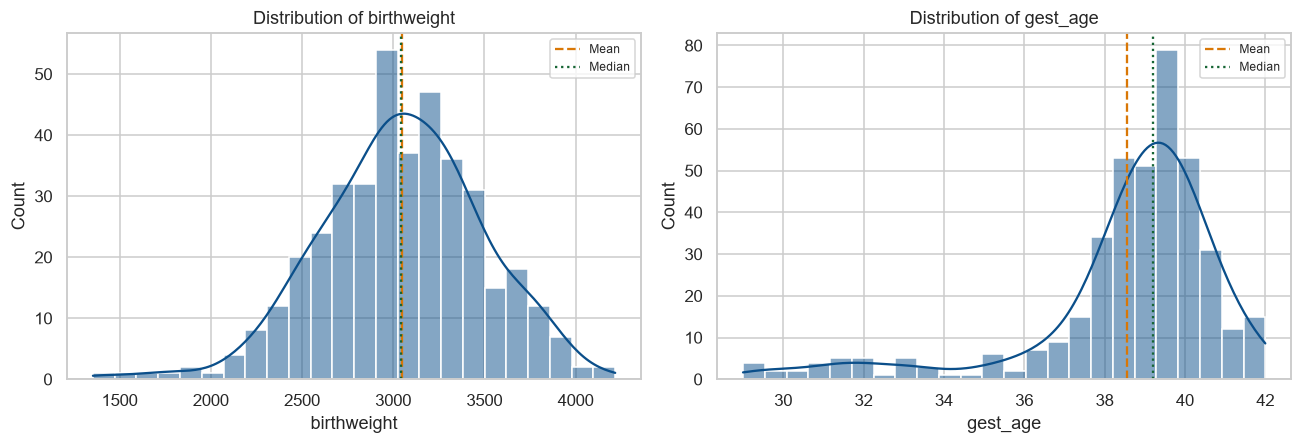

   variable   n     mean   median      sd  skewness  iqr_outliers_low  iqr_outliers_high
birthweight 400 3046.892 3040.500 442.437    -0.308                 5                  1
   gest_age 400   38.560   39.200   2.458    -1.939                36                  0


[{'variable': 'birthweight',
  'n': 400,
  'mean': 3046.8925,
  'median': 3040.5,
  'sd': 442.43707162671626,
  'skewness': -0.30775860211429856,
  'iqr_outliers_low': 5,
  'iqr_outliers_high': 1},
 {'variable': 'gest_age',
  'n': 400,
  'mean': 38.55975,
  'median': 39.2,
  'sd': 2.4581519919522568,
  'skewness': -1.9393228809325516,
  'iqr_outliers_low': 36,
  'iqr_outliers_high': 0}]

In [7]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

dist_columns = ["birthweight", "gest_age"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
dist_rows = []
for axis, column in zip(axes, dist_columns):
    values = anc[column].dropna()
    sns.histplot(values, kde=True, bins=24, ax=axis, color="#0b4f8a")
    axis.axvline(values.mean(), color="#d97706", linestyle="--", label="Mean")
    axis.axvline(values.median(), color="#166534", linestyle=":", label="Median")
    axis.set_title(f"Distribution of {column}")
    axis.legend(fontsize=8)
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    dist_rows.append({
        "variable": column,
        "n": int(values.size),
        "mean": values.mean(),
        "median": values.median(),
        "sd": values.std(ddof=1),
        "skewness": values.skew(),
        "iqr_outliers_low": int((values < low).sum()),
        "iqr_outliers_high": int((values > high).sum()),
    })
plt.tight_layout()
plt.show()
plt.close("all")
q2c_summary = pd.DataFrame(dist_rows)
print(q2c_summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
record("Q2c", q2c_summary.to_dict(orient="records"))


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q2d — Correlation

**Practical requirement.** Examine the relationship between gest_age and birthweight with a scatterplot and two correlations.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Quantify and interpret the association between gestational age and birthweight.
- Statistical concept: Pearson measures linear association; Spearman measures monotone association using ranks.
- Do you need to write code? Yes — one plotting and calculation cell.
- What to do in Jupyter: Run Q2(d) and read the scatterplot before the correlation numbers.
- Code to use: Use the verified Q2(d) code cell.
- Output to inspect: A scatterplot with fitted line, Pearson r with CI and p-value, and Spearman rho with p-value.
- Important values or observations: The sign and size of both coefficients, plus any visible curvature or influential points.
- How to interpret it: Choose the coefficient that matches the observed relationship and the question of interest.
- What to report: Report both coefficients, then state which is more appropriate and why.
- Common mistakes to avoid: Interpreting correlation as causation, or choosing Pearson without looking at the scatterplot.

**Output to inspect.** Scatterplot and both correlation coefficients.

**Interpretation guidance.** A strong positive association means longer gestation tends to accompany higher birthweight in these data; it is not causal proof.

**Reporting guidance.** Report the coefficient(s), p-values if required, and a contextual sentence.

**Worked report from the executed notebook.** Gestational age and birthweight showed a positive association (Pearson r=0.365, 95% CI 0.277 to 0.447, p<0.0001; Spearman rho=0.331, p<0.0001; n=400). The rank-based estimate is close to the Pearson estimate, which is reassuring, but the scatterplot and influence diagnostics are still needed before ruling out influential points.

*Verified source:* Q2c and Q2d outputs · anc_cohort.csv. *Teaching note:* Report both coefficients and inspect the scatterplot first. An observational association is not evidence that gestational age causes birthweight.

**Common mistakes.** Saying correlation proves that gestational age causes birthweight.


**Code cell `q2d`**

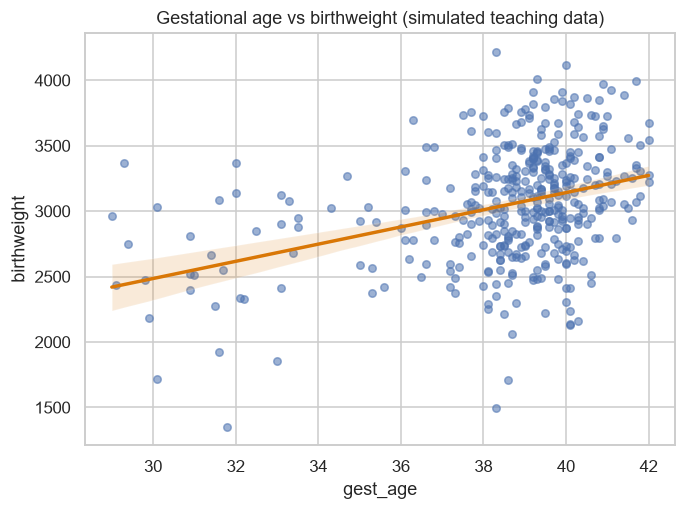

Pearson r  = 0.3647, p = 4.981e-14, 95% CI [0.2765, 0.4468]
Spearman rho = 0.3310, p = 1.104e-11


{'n': 400,
 'pearson_r': 0.36471173662946693,
 'pearson_p': 4.980870139146528e-14,
 'pearson_ci': [0.2765496000320724, 0.4467861112286768],
 'spearman_rho': 0.3310247699384513,
 'spearman_p': 1.1043025045435383e-11}

In [8]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

corr_data = anc[["gest_age", "birthweight"]].dropna()
pearson = st.pearsonr(corr_data["gest_age"], corr_data["birthweight"])
spearman = st.spearmanr(corr_data["gest_age"], corr_data["birthweight"])
pearson_ci = pearson.confidence_interval(confidence_level=0.95)
sns.regplot(
    data=corr_data, x="gest_age", y="birthweight",
    scatter_kws={"alpha": 0.55, "s": 24},
    line_kws={"color": "#d97706"}, ax=None,
)
plt.title("Gestational age vs birthweight (simulated teaching data)")
plt.tight_layout()
plt.show()
plt.close("all")
print(f"Pearson r  = {pearson.statistic:.4f}, p = {pearson.pvalue:.4g}, "
      f"95% CI [{pearson_ci.low:.4f}, {pearson_ci.high:.4f}]")
print(f"Spearman rho = {spearman.statistic:.4f}, p = {spearman.pvalue:.4g}")
record("Q2d", {
    "n": int(len(corr_data)),
    "pearson_r": float(pearson.statistic),
    "pearson_p": float(pearson.pvalue),
    "pearson_ci": [float(pearson_ci.low), float(pearson_ci.high)],
    "spearman_rho": float(spearman.statistic),
    "spearman_p": float(spearman.pvalue),
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [9]:
mark_done("Q2")

Progress: ■■□□□□□□□□  2/10 questions covered


<a id="q3"></a>

## Q3. Estimation and confidence intervals

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q3a | Calculate and verify the 95% CI for mean birthweight using the t distribution. | Calculation | Run Q3(a) and confirm the manual and SciPy endpoints match. | See code cell q3a | All intermediate quantities and matching endpoints. | A 95% confidence procedure captures the true mean in 95% of repeated samples under its assumptions. | Report the interval with the sample mean and state the confidence level correctly. |
| Q3b | Estimate anaemia prevalence and a 95% binomial confidence interval. | Calculation | Run Q3(b) and note the eligible denominator and excluded records. | See code cell q3b | Numerator, denominator, prevalence and Wilson CI. | The interval reflects binomial sampling variability among evaluable records. | State the prevalence with numerator, denominator and interval method. |
| Q3c | Explain confidence intervals, precision and the effect of a fourfold sample size. | Interpretation | Read the guidance and write your answer; no new code is required. | Not required — conceptual/interpretation task. | No new output; interpret earlier intervals. | Confidence describes procedure reliability across repeated samples, not posterior probability for one fixed interval. | Use the template but write the interpretation in your own words. |
| Q3d | Estimate mean birthweight and 95% CIs by facility type and compare them visually. | Mixed | Run Q3(d), inspect the table and the point estimate/CI plot. | See code cell q3d | Three subgroup estimates with CIs and the comparison plot. | Subgroup CIs show precision; a formal comparison requires an appropriate model or test. | Report the three estimates and avoid a definitive equality/difference claim from overlap alone. |


#### Q3a — CI for a mean

**Practical requirement.** Calculate and verify the 95% CI for mean birthweight using the t distribution.
**Task classification.** Calculation
**Code required.** Yes

**Learning guide**

- What is being asked? Build a t-based confidence interval step by step and verify it in SciPy.
- Statistical concept: The standard error is SD/sqrt(n); the critical value comes from t with n-1 degrees of freedom.
- Do you need to write code? Yes — one manual calculation cell.
- What to do in Jupyter: Run Q3(a) and read each intermediate quantity in the table.
- Code to use: Use the verified Q3(a) code cell.
- Output to inspect: A table of mean, SD, n, df, SE, critical t and both pairs of CI endpoints.
- Important values or observations: Manual lower/upper and SciPy lower/upper agree within numerical precision.
- How to interpret it: This is an interval for the population mean, estimated from the sample.
- What to report: Report the mean, SE, df, critical value and the 95% CI.
- Common mistakes to avoid: Using z instead of t without justification, or saying there is a 95% chance the true mean lies in this fixed interval.

**Output to inspect.** All intermediate quantities and matching endpoints.

**Interpretation guidance.** A 95% confidence procedure captures the true mean in 95% of repeated samples under its assumptions.

**Reporting guidance.** Report the interval with the sample mean and state the confidence level correctly.

**Worked report from the executed notebook.** Mean birthweight was 3,046.89 g (SD 442.44, n=400, df=399); SE = SD/sqrt(n) = 22.12 g and the critical t value is 1.966. The 95% t interval was 3,003.40 to 3,090.38 g, matching the SciPy endpoints 3,003.40 to 3,090.38 g.

*Verified source:* Q3a output · anc_cohort.csv. *Teaching note:* The interval targets the population mean, not the range of individual births. A 95% procedure has long-run coverage under its assumptions.

**Common mistakes.** The common '95% probability the fixed interval contains the mean' misinterpretation.


**Code cell `q3a`**

In [10]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

bw = anc["birthweight"].dropna()
n = int(bw.size)
mean_bw = float(bw.mean())
sd_bw = float(bw.std(ddof=1))
se_bw = sd_bw / np.sqrt(n)
df_bw = n - 1
t_crit = float(st.t.ppf(0.975, df_bw))
manual_ci = (mean_bw - t_crit * se_bw, mean_bw + t_crit * se_bw)
scipy_ci = st.t.interval(0.95, df=df_bw, loc=mean_bw, scale=se_bw)
steps = pd.DataFrame({
    "quantity": ["Sample mean", "Sample SD", "n", "df", "Standard error",
                 "Critical t (0.975)", "Manual lower", "Manual upper",
                 "SciPy lower", "SciPy upper"],
    "value": [mean_bw, sd_bw, n, df_bw, se_bw, t_crit,
              manual_ci[0], manual_ci[1], scipy_ci[0], scipy_ci[1]],
})
print(steps.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print(f"Manual and SciPy endpoints agree to <1e-9: "
      f"{np.allclose(manual_ci, scipy_ci, atol=1e-9)}")
record("Q3a", {
    "n": n, "mean": mean_bw, "sd": sd_bw, "se": se_bw, "df": df_bw,
    "t_critical": t_crit, "ci": [float(manual_ci[0]), float(manual_ci[1])],
    "scipy_ci": [float(scipy_ci[0]), float(scipy_ci[1])],
})


          quantity       value
       Sample mean 3046.892500
         Sample SD  442.437072
                 n  400.000000
                df  399.000000
    Standard error   22.121854
Critical t (0.975)    1.965927
      Manual lower 3003.402544
      Manual upper 3090.382456
       SciPy lower 3003.402544
       SciPy upper 3090.382456
Manual and SciPy endpoints agree to <1e-9: True


{'n': 400,
 'mean': 3046.8925,
 'sd': 442.43707162671626,
 'se': 22.121853581335813,
 'df': 399,
 't_critical': 1.9659272959208818,
 'ci': [3003.4025442080865, 3090.3824557919133],
 'scipy_ci': [3003.4025442080865, 3090.3824557919133]}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q3b — CI for a prevalence

**Practical requirement.** Estimate anaemia prevalence and a 95% binomial confidence interval.
**Task classification.** Calculation
**Code required.** Yes

**Learning guide**

- What is being asked? Estimate a binary outcome prevalence with an appropriate binomial interval.
- Statistical concept: The denominator is the number of non-missing anaemia records; Wilson is suitable for proportions.
- Do you need to write code? Yes — one calculation cell.
- What to do in Jupyter: Run Q3(b) and read the event count, denominator and Wilson interval.
- Code to use: Use the verified Q3(b) code cell.
- Output to inspect: Event count, eligible denominator, prevalence, Wilson CI and number excluded.
- Important values or observations: 139 events out of 382 evaluable records; 18 records excluded because anaemia is missing.
- How to interpret it: Missingness must be reported so the denominator is auditable.
- What to report: Report the numerator, denominator, prevalence and CI method.
- Common mistakes to avoid: Using all 400 as the denominator, or using a normal approximation without checking counts.

**Output to inspect.** Numerator, denominator, prevalence and Wilson CI.

**Interpretation guidance.** The interval reflects binomial sampling variability among evaluable records.

**Reporting guidance.** State the prevalence with numerator, denominator and interval method.

**Worked report from the executed notebook.** Anaemia prevalence was 139/382 = 0.3639 (36.39%), with 18 records excluded because anaemia was missing. The 95% Wilson interval was 31.72% to 41.33%.

*Verified source:* Q3b output · anc_cohort.csv. *Teaching note:* State the evaluable denominator and exclusions. The interval describes prevalence, not an individual woman's probability of anaemia.

**Common mistakes.** Hiding the 18 missing observations.


**Code cell `q3b`**

In [11]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

anaemia = anc["anaemia"].dropna().astype(int)
events = int(anaemia.sum())
denominator = int(anaemia.size)
prevalence = events / denominator
wilson_ci = proportion_confint(events, denominator, alpha=0.05, method="wilson")
print(f"Anaemia events: {events}")
print(f"Eligible non-missing denominator: {denominator}")
print(f"Prevalence: {prevalence:.4f} ({prevalence * 100:.2f}%)")
print(f"Wilson 95% CI: [{wilson_ci[0]:.4f}, {wilson_ci[1]:.4f}]")
print(f"Records excluded from denominator: {int(anc['anaemia'].isna().sum())}")
record("Q3b", {
    "events": events, "denominator": denominator,
    "prevalence": float(prevalence),
    "ci": [float(wilson_ci[0]), float(wilson_ci[1])],
    "missing_excluded": int(anc["anaemia"].isna().sum()),
})


Anaemia events: 139
Eligible non-missing denominator: 382
Prevalence: 0.3639 (36.39%)
Wilson 95% CI: [0.3172, 0.4133]
Records excluded from denominator: 18


{'events': 139,
 'denominator': 382,
 'prevalence': 0.36387434554973824,
 'ci': [0.3172050127096916, 0.4132542274199954],
 'missing_excluded': 18}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q3c — Interpret a confidence interval

**Practical requirement.** Explain confidence intervals, precision and the effect of a fourfold sample size.
**Task classification.** Interpretation
**Code required.** No

**Learning guide**

- What is being asked? Interpret what a 95% confidence interval does and does not mean.
- Statistical concept: Confidence level refers to the long-run performance of the interval procedure; width shrinks roughly with 1/sqrt(n).
- Do you need to write code? No — this is interpretation.
- What to do in Jupyter: Write a short explanation using the Q3(a) and Q3(b) intervals as examples.
- Code to use: No new code is required; reuse the verified outputs.
- Output to inspect: Your written interpretation, not a new table.
- Important values or observations: The interval width and the sample sizes from Q3(a) and Q3(b).
- How to interpret it: A larger sample gives a narrower interval, all else equal; four times n roughly halves the width.
- What to report: Report a correct frequentist interpretation and a precision statement.
- Common mistakes to avoid: Reversing the logic of confidence, or promising that quadrupling n always halves width exactly.

**Output to inspect.** No new output; interpret earlier intervals.

**Interpretation guidance.** Confidence describes procedure reliability across repeated samples, not posterior probability for one fixed interval.

**Reporting guidance.** Use the template but write the interpretation in your own words.

**Worked report from the executed notebook.** The Q3a interval for mean birthweight is 3,003.40 to 3,090.38 g (width 86.98 g; n=400), while the Q3b interval for anaemia prevalence is 31.72% to 41.33% (n=382). A 95% confidence level is a long-run property of the interval procedure. Other things equal, four times the sample size divides the standard error, and therefore approximately the interval width, by two.

*Verified source:* Q3a and Q3b outputs · anc_cohort.csv. *Teaching note:* Do not say there is a 95% probability that the fixed parameter lies in this one interval. The two intervals also have different denominators and answer different questions.

**Common mistakes.** The '95% chance the true value is in this interval' wording.


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q3d — Facility-specific estimates

**Practical requirement.** Estimate mean birthweight and 95% CIs by facility type and compare them visually.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Compare subgroup means and their uncertainty without over-reading interval overlap.
- Statistical concept: Separate t intervals describe each subgroup mean; overlap is not a formal test of equality.
- Do you need to write code? Yes — one estimation and plotting cell.
- What to do in Jupyter: Run Q3(d) and compare Urban, Peri-urban and Rural estimates and interval widths.
- Code to use: Use the verified Q3(d) code cell.
- Output to inspect: A subgroup summary table and a point plot with 95% CIs.
- Important values or observations: Subgroup n, means and interval endpoints.
- How to interpret it: Intervals that overlap do not prove means are equal, and non-overlap is not the only way to detect a difference.
- What to report: Report each subgroup estimate with n and CI, then describe patterns cautiously.
- Common mistakes to avoid: Using interval overlap as a significance test, or ignoring unequal subgroup sizes.

**Output to inspect.** Three subgroup estimates with CIs and the comparison plot.

**Interpretation guidance.** Subgroup CIs show precision; a formal comparison requires an appropriate model or test.

**Reporting guidance.** Report the three estimates and avoid a definitive equality/difference claim from overlap alone.

**Worked report from the executed notebook.** Mean birthweight was Urban 3,110.44 g (n=154, 95% CI 3,038.47 to 3,182.41); Peri-urban 2,989.60 g (n=133, 95% CI 2,915.44 to 3,063.77); Rural 3,027.72 g (n=113, 95% CI 2,946.90 to 3,108.53). These separate intervals show precision within each facility group; overlap alone is not a formal test of equal means.

*Verified source:* Q3d output · anc_cohort.csv. *Teaching note:* A formal comparison requires a model-based approach such as the birthweight model in Q8d. Unequal subgroup sample sizes make interval widths hard to compare informally.

**Common mistakes.** Treating overlapping CIs as proof of no difference.


**Code cell `q3d`**

facility_type   n    mean     sd  ci_low  ci_high
        Urban 154 3110.44 452.08 3038.47  3182.41
   Peri-urban 133 2989.60 432.40 2915.44  3063.77
        Rural 113 3027.72 433.59 2946.90  3108.53

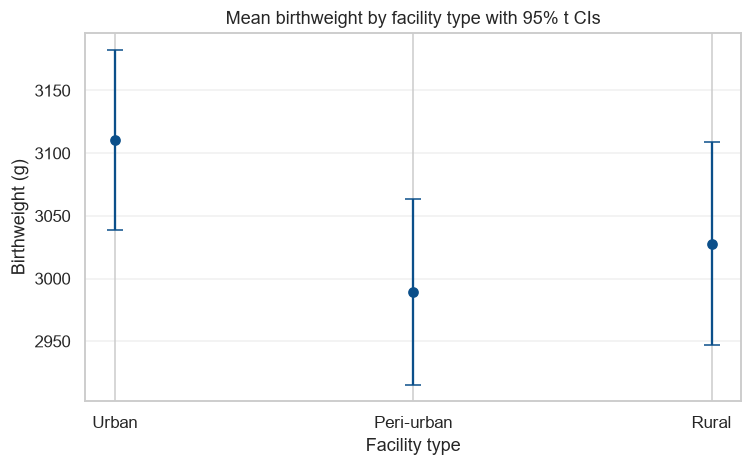

[{'facility_type': 'Urban',
  'n': 154,
  'mean': 3110.4415584415583,
  'sd': 452.0772966907057,
  'ci_low': 3038.471935834726,
  'ci_high': 3182.4111810483905},
 {'facility_type': 'Peri-urban',
  'n': 133,
  'mean': 2989.6015037593984,
  'sd': 432.39728049507863,
  'ci_low': 2915.435458461391,
  'ci_high': 3063.7675490574056},
 {'facility_type': 'Rural',
  'n': 113,
  'mean': 3027.716814159292,
  'sd': 433.58508534383066,
  'ci_low': 2946.900117701391,
  'ci_high': 3108.533510617193}]

In [12]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

facility_order = ["Urban", "Peri-urban", "Rural"]
facility_rows = []
for facility in facility_order:
    values = anc.loc[anc["facility_type"] == facility, "birthweight"].dropna()
    n_f = int(values.size)
    mean_f = float(values.mean())
    sd_f = float(values.std(ddof=1))
    se_f = sd_f / np.sqrt(n_f)
    ci_f = st.t.interval(0.95, df=n_f - 1, loc=mean_f, scale=se_f)
    facility_rows.append({
        "facility_type": facility, "n": n_f, "mean": mean_f, "sd": sd_f,
        "ci_low": ci_f[0], "ci_high": ci_f[1],
    })
facility_summary = pd.DataFrame(facility_rows)
print(facility_summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# Plot the same deterministic t intervals shown in the table. Seaborn's
# errorbar=("ci", 95) is a bootstrap interval and would not match them.
x_positions = np.arange(len(facility_order))
yerr = np.array([
    facility_summary["mean"] - facility_summary["ci_low"],
    facility_summary["ci_high"] - facility_summary["mean"],
])
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.errorbar(x_positions, facility_summary["mean"], yerr=yerr,
            fmt="o", capsize=5, color="#0b4f8a")
ax.set_xticks(x_positions, facility_order)
ax.set_title("Mean birthweight by facility type with 95% t CIs")
ax.set_xlabel("Facility type")
ax.set_ylabel("Birthweight (g)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close("all")
record("Q3d", facility_summary.to_dict(orient="records"))


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [13]:
mark_done("Q3")

Progress: ■■■□□□□□□□  3/10 questions covered


<a id="q4"></a>

## Q4. Comparing mean birthweight by IPTp3 status

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q4 | Compare birthweight between IPTp3 Yes and No groups using Welch's t-test and a rank-sum analysis. | Mixed | Run Q4, inspect group summaries, plots, Levene, Welch and Wilcoxon outputs. | See code cell q4 | All group, assumption-check and test outputs. | Focus on the size and precision of the mean difference, not only the p-value. | Use the independent-groups template and add the observational limitation. |


#### Q4 — IPTp3 and birthweight

**Practical requirement.** Compare birthweight between IPTp3 Yes and No groups using Welch's t-test and a rank-sum analysis.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Analyse an independent two-group observational comparison.
- Statistical concept: Welch's t-test compares means without assuming equal variances; Wilcoxon rank-sum compares distributions/ranks.
- Do you need to write code? Yes — one comprehensive analysis cell.
- What to do in Jupyter: Run Q4 and read each output block in order.
- Code to use: Use the verified Q4 code cell.
- Output to inspect: Group summaries, boxplot/histograms, Levene p, Welch t/df/p/CI and rank-sum result.
- Important values or observations: Mean difference, its CI and whether the p-value is small; Levene is an assumption check, while Welch is used throughout.
- How to interpret it: Statistical significance does not imply clinical importance, and an observational comparison is not causal.
- What to report: Report group n/mean/SD, the Welch difference with CI and p, and the sensitivity analysis.
- Common mistakes to avoid: Calling rank-sum automatically a median test, or claiming IPTp3 caused a birthweight change.

**Output to inspect.** All group, assumption-check and test outputs.

**Interpretation guidance.** Focus on the size and precision of the mean difference, not only the p-value.

**Reporting guidance.** Use the independent-groups template and add the observational limitation.

**Worked report from the executed notebook.** Mean birthweight was 3,125.79 g with IPTp3 Yes (n=243) and 2,924.78 g with No (n=157), a difference of 201.00 g (Yes minus No; Welch 95% CI 112.76 to 289.24; t=4.48, df=317.4, p<0.0001). Levene p=0.8128 and rank-sum p<0.0001 give context for the assumption check and sensitivity analysis.

*Verified source:* Q4 output · anc_cohort.csv. *Teaching note:* Welch's test does not assume equal variances. Report the size and precision of the difference and keep the wording observational, not causal.

**Common mistakes.** Using Student's pooled t-test despite unequal variances, or making a causal claim.


**Code cell `q4`**

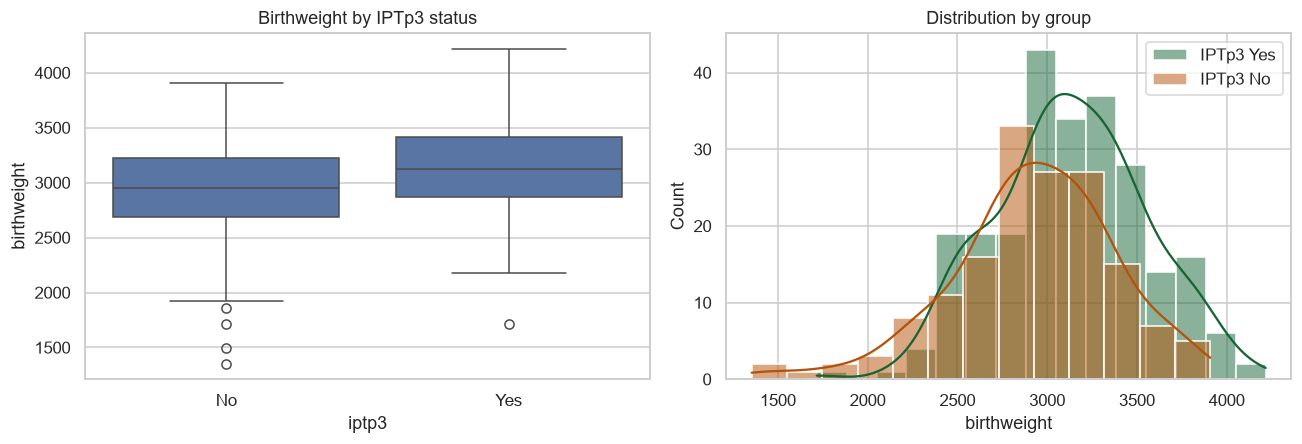

iptp3   n    mean     sd  median
  Yes 243 3125.79 420.65 3126.00
   No 157 2924.78 448.86 2947.00
Levene p = 0.8128
Welch t = 4.4817, df = 317.39, p = 1.035e-05
Mean difference (Yes - No) = 201.00 g, 95% CI [112.76, 289.24]
Wilcoxon rank-sum U = 23734.5, p = 3.694e-05, rank-biserial r = 0.244


{'groups': [{'iptp3': 'Yes',
   'n': 243,
   'mean': 3125.786008230453,
   'sd': 420.646535392015,
   'median': 3126.0},
  {'iptp3': 'No',
   'n': 157,
   'mean': 2924.7834394904457,
   'sd': 448.86395515435635,
   'median': 2947.0}],
 'levene_p': 0.8127607421602898,
 'welch_t': 4.481724050216285,
 'welch_df': 317.3866489321943,
 'welch_p': 1.0351764378014585e-05,
 'mean_difference': 201.00256874000706,
 'welch_ci': [112.76290683794944, 289.24223064206467],
 'mann_whitney_u': 23734.5,
 'mann_whitney_p': 3.693814467947495e-05,
 'rank_biserial': 0.24423999370920813}

In [14]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

yes = anc.loc[anc["iptp3"] == "Yes", "birthweight"].dropna()
no = anc.loc[anc["iptp3"] == "No", "birthweight"].dropna()
group_summary = pd.DataFrame({
    "iptp3": ["Yes", "No"],
    "n": [int(yes.size), int(no.size)],
    "mean": [yes.mean(), no.mean()],
    "sd": [yes.std(ddof=1), no.std(ddof=1)],
    "median": [yes.median(), no.median()],
})
levene = st.levene(yes, no, center="median")
welch = st.ttest_ind(yes, no, equal_var=False)
welch_ci = welch.confidence_interval(confidence_level=0.95)
mean_diff = yes.mean() - no.mean()
mann = st.mannwhitneyu(yes, no, alternative="two-sided")
rank_biserial = 2 * mann.statistic / (yes.size * no.size) - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=anc, x="iptp3", y="birthweight", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Birthweight by IPTp3 status")
sns.histplot(yes, kde=True, color="#166534", label="IPTp3 Yes", ax=axes[1])
sns.histplot(no, kde=True, color="#b45309", label="IPTp3 No", ax=axes[1])
axes[1].set_title("Distribution by group")
axes[1].legend()
plt.tight_layout()
plt.show()
plt.close("all")

print(group_summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"Levene p = {levene.pvalue:.4f}")
print(f"Welch t = {welch.statistic:.4f}, df = {welch.df:.2f}, "
      f"p = {welch.pvalue:.4g}")
print(f"Mean difference (Yes - No) = {mean_diff:.2f} g, "
      f"95% CI [{welch_ci.low:.2f}, {welch_ci.high:.2f}]")
print(f"Wilcoxon rank-sum U = {mann.statistic:.1f}, p = {mann.pvalue:.4g}, "
      f"rank-biserial r = {rank_biserial:.3f}")
record("Q4", {
    "groups": group_summary.to_dict(orient="records"),
    "levene_p": float(levene.pvalue),
    "welch_t": float(welch.statistic), "welch_df": float(welch.df),
    "welch_p": float(welch.pvalue), "mean_difference": float(mean_diff),
    "welch_ci": [float(welch_ci.low), float(welch_ci.high)],
    "mann_whitney_u": float(mann.statistic),
    "mann_whitney_p": float(mann.pvalue),
    "rank_biserial": float(rank_biserial),
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [15]:
mark_done("Q4")

Progress: ■■■■□□□□□□  4/10 questions covered


<a id="q5"></a>

## Q5. Paired t-test for blood pressure

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q5 | Compare booking and 36-week systolic BP using a paired analysis. | Mixed | Run Q5, inspect the paired difference plot, normality check and paired t result. | See code cell q5 | Paired difference output and the contrast with the incorrect independent test. | The paired test asks whether the mean within-person difference differs from zero. | Report booking mean, 36-week mean, mean change, CI and p-value. |


#### Q5 — Paired blood-pressure test

**Practical requirement.** Compare booking and 36-week systolic BP using a paired analysis.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Analyse two measurements taken on the same women.
- Statistical concept: Pairing removes between-woman variability by analysing within-woman differences.
- Do you need to write code? Yes — one paired-analysis cell.
- What to do in Jupyter: Run Q5 and compare the paired result with the deliberately incorrect independent result.
- Code to use: Use the verified Q5 code cell.
- Output to inspect: Summaries, difference histogram, paired profiles, Shapiro result, paired t/CI/p and incorrect independent test.
- Important values or observations: Mean change, CI, p-value and the difference between the correct and incorrect standard errors.
- How to interpret it: A bigger mean at 36 weeks is an average within-woman change in this simulated cohort.
- What to report: Report the mean paired change with CI and p-value, and explain why pairing is required.
- Common mistakes to avoid: Using an independent-samples test for the final inference or ignoring the id linkage.

**Output to inspect.** Paired difference output and the contrast with the incorrect independent test.

**Interpretation guidance.** The paired test asks whether the mean within-person difference differs from zero.

**Reporting guidance.** Report booking mean, 36-week mean, mean change, CI and p-value.

**Worked report from the executed notebook.** Among 60 paired women, mean systolic blood pressure was 112.20 mmHg at booking and 115.87 mmHg at 36 weeks. The mean within-woman change was 3.67 mmHg (95% CI 1.36 to 5.98; paired t=3.17, p=0.0024), whereas the incorrect independent test gives p=0.0848 because it ignores the id linkage.

*Verified source:* Q5 output · bp_paired.csv. *Teaching note:* Analyse the 60 paired differences, not 120 independent observations. Shapiro-Wilk and the paired-difference plot support checking the t assumption.

**Common mistakes.** Treating 120 observations as independent when there are only 60 women.


**Code cell `q5`**

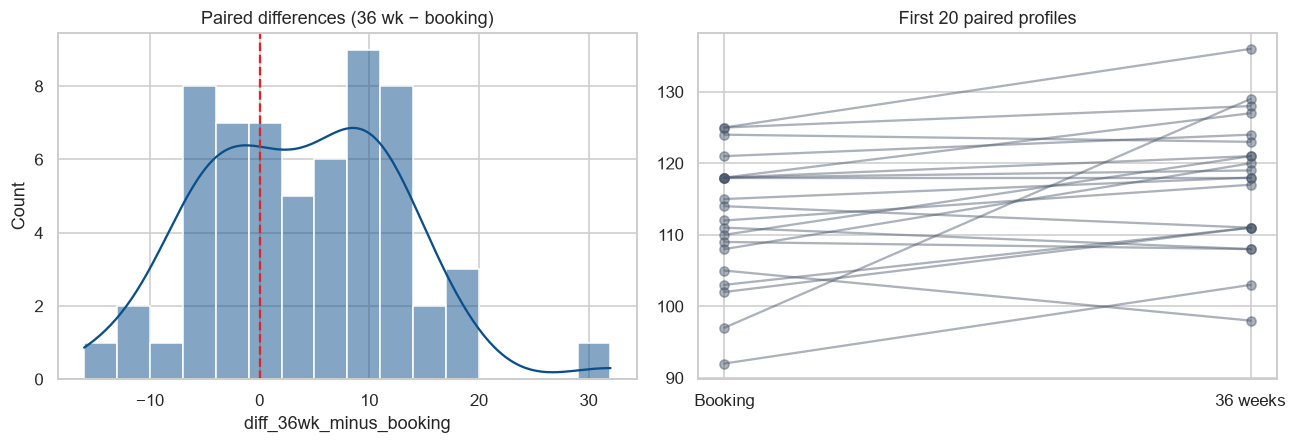

          measure  n    mean     sd
      sbp_booking 60 112.200 10.358
         sbp_36wk 60 115.867 12.630
paired difference 60   3.667  8.947
Shapiro-Wilk on differences: W = 0.9766, p = 0.3026
Paired t = 3.1743, p = 0.002387
Mean change = 3.667 mmHg, 95% CI [1.355, 5.978]
Incorrect independent Welch t = 1.7389, p = 0.08477


{'summary': [{'measure': 'sbp_booking',
   'n': 60,
   'mean': 112.2,
   'sd': 10.357671356642062},
  {'measure': 'sbp_36wk',
   'n': 60,
   'mean': 115.86666666666666,
   'sd': 12.629621713763573},
  {'measure': 'paired difference',
   'n': 60,
   'mean': 3.6666666666666665,
   'sd': 8.947429640692416}],
 'shapiro_w': 0.9766186743585408,
 'shapiro_p': 0.3026484033803393,
 'paired_t': 3.1743058076721327,
 'paired_p': 0.0023870066397307338,
 'mean_change': 3.6666666666666665,
 'ci': [1.3553004979575256, 5.978032835375807],
 'incorrect_independent_t': 1.7388548850262389,
 'incorrect_independent_p': 0.08476830371404064}

In [16]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

paired = bp.copy()
paired["diff_36wk_minus_booking"] = paired["sbp_36wk"] - paired["sbp_booking"]
diff = paired["diff_36wk_minus_booking"]
bp_summary = pd.DataFrame({
    "measure": ["sbp_booking", "sbp_36wk", "paired difference"],
    "n": [int(paired["sbp_booking"].notna().sum()),
          int(paired["sbp_36wk"].notna().sum()), int(diff.notna().sum())],
    "mean": [paired["sbp_booking"].mean(), paired["sbp_36wk"].mean(), diff.mean()],
    "sd": [paired["sbp_booking"].std(ddof=1), paired["sbp_36wk"].std(ddof=1),
           diff.std(ddof=1)],
})
shapiro = st.shapiro(diff)
paired_test = st.ttest_rel(paired["sbp_36wk"], paired["sbp_booking"])
paired_ci = paired_test.confidence_interval(confidence_level=0.95)
wrong_independent = st.ttest_ind(
    paired["sbp_36wk"], paired["sbp_booking"], equal_var=False
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(diff, kde=True, bins=16, ax=axes[0], color="#0b4f8a")
axes[0].axvline(0, color="#dc2626", linestyle="--")
axes[0].set_title("Paired differences (36 wk − booking)")
for _, row in paired.head(20).iterrows():
    axes[1].plot([0, 1], [row["sbp_booking"], row["sbp_36wk"]],
                marker="o", alpha=0.45, color="#475569")
axes[1].set_xticks([0, 1], ["Booking", "36 weeks"])
axes[1].set_title("First 20 paired profiles")
plt.tight_layout()
plt.show()
plt.close("all")

print(bp_summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"Shapiro-Wilk on differences: W = {shapiro.statistic:.4f}, "
      f"p = {shapiro.pvalue:.4f}")
print(f"Paired t = {paired_test.statistic:.4f}, p = {paired_test.pvalue:.4g}")
print(f"Mean change = {diff.mean():.3f} mmHg, "
      f"95% CI [{paired_ci.low:.3f}, {paired_ci.high:.3f}]")
print(f"Incorrect independent Welch t = {wrong_independent.statistic:.4f}, "
      f"p = {wrong_independent.pvalue:.4g}")
record("Q5", {
    "summary": bp_summary.to_dict(orient="records"),
    "shapiro_w": float(shapiro.statistic), "shapiro_p": float(shapiro.pvalue),
    "paired_t": float(paired_test.statistic), "paired_p": float(paired_test.pvalue),
    "mean_change": float(diff.mean()),
    "ci": [float(paired_ci.low), float(paired_ci.high)],
    "incorrect_independent_t": float(wrong_independent.statistic),
    "incorrect_independent_p": float(wrong_independent.pvalue),
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [17]:
mark_done("Q5")

Progress: ■■■■■□□□□□  5/10 questions covered


<a id="q6"></a>

## Q6. ANOVA and non-parametric comparison

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q6 | Compare haemoglobin across facility types with ANOVA, Tukey HSD and Kruskal-Wallis. | Mixed | Run Q6, inspect assumptions, overall tests and adjusted pairwise comparisons. | See code cell q6 | All ANOVA, diagnostic and post-hoc outputs. | Use the overall test to justify post-hoc comparisons and report adjusted p-values. | Report F, df, p, then Tukey differences with CIs and adjusted p-values where relevant. |


#### Q6 — ANOVA and non-parametric comparison

**Practical requirement.** Compare haemoglobin across facility types with ANOVA, Tukey HSD and Kruskal-Wallis.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Compare three independent groups and handle multiplicity.
- Statistical concept: One-way ANOVA compares means; Alexander-Govern provides a heteroscedastic alternative; Kruskal-Wallis compares distributions/ranks; Tukey HSD adjusts pairwise comparisons under equal variances.
- Do you need to write code? Yes — one comparison cell.
- What to do in Jupyter: Run Q6 and read the boxplot, residual plot, Levene, ANOVA, Tukey table, Alexander-Govern and Kruskal results.
- Code to use: Use the verified Q6 code cell.
- Output to inspect: Group summaries, diagnostic plots, Levene p, ANOVA F/df/p, Tukey adjusted comparisons, Alexander-Govern A/p and Kruskal H/p.
- Important values or observations: The overall p-value, which Tukey pairs differ and whether Levene's significant result shifts emphasis to Alexander-Govern/Kruskal.
- How to interpret it: A significant overall test does not say which groups differ; post-hoc tests must account for multiplicity.
- What to report: Report the overall test first, then adjusted pairwise differences only if warranted.
- Common mistakes to avoid: Running unadjusted pairwise t-tests and calling them pre-planned, or ignoring assumption checks.

**Output to inspect.** All ANOVA, diagnostic and post-hoc outputs.

**Interpretation guidance.** Use the overall test to justify post-hoc comparisons and report adjusted p-values.

**Reporting guidance.** Report F, df, p, then Tukey differences with CIs and adjusted p-values where relevant.

**Worked report from the executed notebook.** One-way ANOVA comparing haemoglobin across facility type gave F(2,379)=11.36, p<0.0001; Levene p=0.0433, Alexander-Govern A=20.57 (p<0.0001) and Kruskal-Wallis H=18.54, p<0.0001. Because Levene is significant, the equal-variance ANOVA/Tukey results are assumption-dependent; the Alexander-Govern and rank-based tests are the preferred sensitivity checks here. Tukey-adjusted pairwise differences were: Rural minus Peri-urban = -0.11 g/dL (95% CI -0.53 to 0.32, adjusted p=0.8222); Urban minus Peri-urban = 0.64 g/dL (95% CI 0.24 to 1.03, adjusted p=0.0005); Urban minus Rural = 0.75 g/dL (95% CI 0.33 to 1.16, adjusted p=0.0001).

*Verified source:* Q6 output · anc_cohort.csv. *Teaching note:* Report the heteroscedastic and rank-based results before relying on classical ANOVA/Tukey when Levene is significant. Tukey differences are written in the same direction statsmodels computes them: group2 minus group1.

**Common mistakes.** Treating each pairwise comparison as an independent primary question.


**Code cell `q6`**

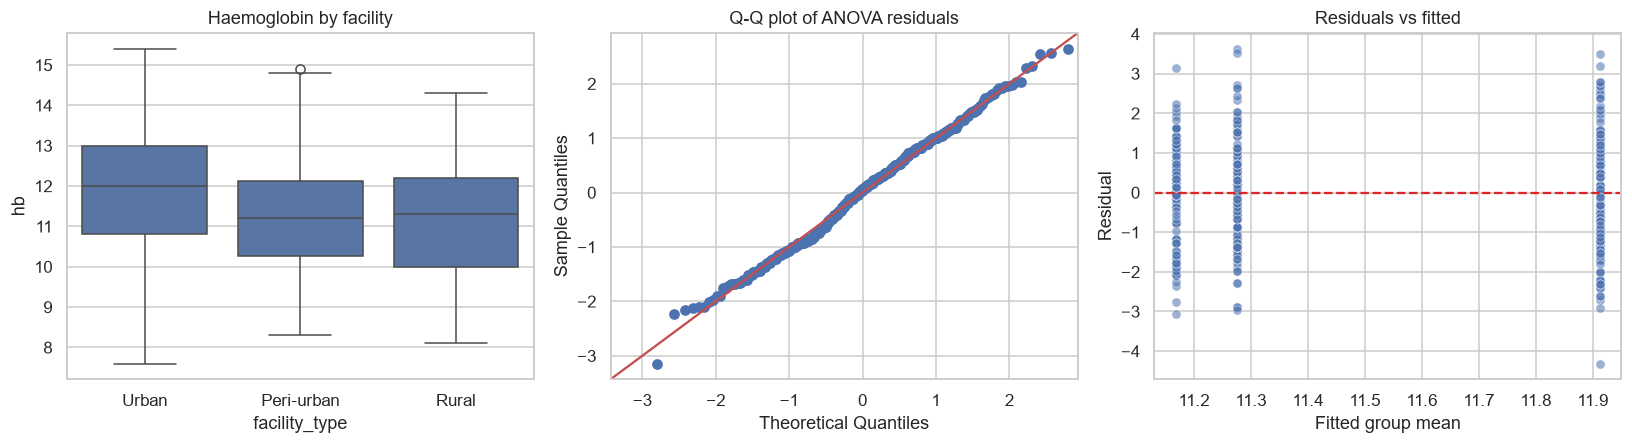

facility_type   n   mean    sd  median
        Urban 145 11.913 1.499  12.000
   Peri-urban 128 11.275 1.325  11.200
        Rural 109 11.168 1.267  11.300
Levene p = 0.0433
One-way ANOVA: F(2,379) = 11.365, p = 1.609e-05

Tukey HSD (equal-variance assumption; multiplicity-adjusted):
    group1 group2  meandiff  p-adj   lower  upper  reject
Peri-urban  Rural   -0.1071 0.8222 -0.5298 0.3156   False
Peri-urban  Urban    0.6381 0.0005  0.2448 1.0314    True
     Rural  Urban    0.7452 0.0001  0.3341 1.1563    True

Alexander-Govern test for unequal variances: A = 20.5697, p = 3.415e-05
Kruskal-Wallis H = 18.5428, p = 9.408e-05


{'groups': [{'facility_type': 'Urban',
   'n': 145,
   'mean': 11.913103448275862,
   'sd': 1.498946628859274,
   'median': 12.0},
  {'facility_type': 'Peri-urban',
   'n': 128,
   'mean': 11.275,
   'sd': 1.3251058492856422,
   'median': 11.2},
  {'facility_type': 'Rural',
   'n': 109,
   'mean': 11.16788990825688,
   'sd': 1.267242612769724,
   'median': 11.3}],
 'levene_p': 0.04328237430035785,
 'anova_f': 11.364796463021328,
 'anova_p': 1.609424137127712e-05,
 'anova_df_between': 2,
 'anova_df_within': 379,
 'tukey': [{'group1': 'Peri-urban',
   'group2': 'Rural',
   'meandiff': -0.1071,
   'p-adj': 0.8222,
   'lower': -0.5298,
   'upper': 0.3156,
   'reject': False},
  {'group1': 'Peri-urban',
   'group2': 'Urban',
   'meandiff': 0.6381,
   'p-adj': 0.0005,
   'lower': 0.2448,
   'upper': 1.0314,
   'reject': True},
  {'group1': 'Rural',
   'group2': 'Urban',
   'meandiff': 0.7452,
   'p-adj': 0.0001,
   'lower': 0.3341,
   'upper': 1.1563,
   'reject': True}],
 'alexander_govern_

In [18]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

facility_order = ["Urban", "Peri-urban", "Rural"]
hb_groups = [anc.loc[anc["facility_type"] == f, "hb"].dropna()
             for f in facility_order]
hb_summary = pd.DataFrame({
    "facility_type": facility_order,
    "n": [int(g.size) for g in hb_groups],
    "mean": [g.mean() for g in hb_groups],
    "sd": [g.std(ddof=1) for g in hb_groups],
    "median": [g.median() for g in hb_groups],
})
levene_hb = st.levene(*hb_groups, center="median")
anova = st.f_oneway(*hb_groups)
anova_df_between = len(hb_groups) - 1
anova_df_within = int(anc["hb"].notna().sum()) - len(hb_groups)
tukey = pairwise_tukeyhsd(
    anc["hb"].dropna(),
    anc.loc[anc["hb"].notna(), "facility_type"],
    alpha=0.05,
)
tukey_data = tukey.summary().data
tukey_df = pd.DataFrame(tukey_data[1:], columns=tukey_data[0])
# Levene is significant on these data, so report a heteroscedastic
# alternative and treat classical ANOVA/Tukey as assumption-dependent.
alex_govern = st.alexandergovern(*hb_groups)
kruskal = st.kruskal(*hb_groups)

temp = anc.loc[anc["hb"].notna(), ["facility_type", "hb"]].copy()
temp["residual"] = temp["hb"] - temp.groupby("facility_type")["hb"].transform("mean")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.boxplot(data=temp, x="facility_type", y="hb", order=facility_order, ax=axes[0])
axes[0].set_title("Haemoglobin by facility")
sm.qqplot(temp["residual"], line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q plot of ANOVA residuals")
sns.scatterplot(x=temp.groupby("facility_type")["hb"].transform("mean"),
                y=temp["residual"], alpha=0.55, ax=axes[2])
axes[2].axhline(0, color="#dc2626", linestyle="--")
axes[2].set_xlabel("Fitted group mean")
axes[2].set_ylabel("Residual")
axes[2].set_title("Residuals vs fitted")
plt.tight_layout()
plt.show()
plt.close("all")

print(hb_summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"Levene p = {levene_hb.pvalue:.4f}")
print(f"One-way ANOVA: F({anova_df_between},{anova_df_within}) = "
      f"{anova.statistic:.3f}, p = {anova.pvalue:.4g}")
print("\nTukey HSD (equal-variance assumption; multiplicity-adjusted):")
print(tukey_df.to_string(index=False))
print(f"\nAlexander-Govern test for unequal variances: A = "
      f"{alex_govern.statistic:.4f}, p = {alex_govern.pvalue:.4g}")
print(f"Kruskal-Wallis H = {kruskal.statistic:.4f}, p = {kruskal.pvalue:.4g}")
record("Q6", {
    "groups": hb_summary.to_dict(orient="records"),
    "levene_p": float(levene_hb.pvalue),
    "anova_f": float(anova.statistic), "anova_p": float(anova.pvalue),
    "anova_df_between": int(anova_df_between),
    "anova_df_within": int(anova_df_within),
    "tukey": tukey_df.to_dict(orient="records"),
    "alexander_govern_a": float(alex_govern.statistic),
    "alexander_govern_p": float(alex_govern.pvalue),
    "kruskal_h": float(kruskal.statistic), "kruskal_p": float(kruskal.pvalue),
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [19]:
mark_done("Q6")

Progress: ■■■■■■□□□□  6/10 questions covered


<a id="q7"></a>

## Q7. Categorical data and proportions

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q7a | Examine the association between education and anaemia with a contingency table and chi-square test. | Mixed | Run Q7(a), inspect counts, percentages, expected counts and the chi-square result. | See code cell q7a | Observed/expected tables and chi-square output. | Large deviations from expected counts indicate association; the p-value quantifies evidence against independence. | Report counts, percentages and the chi-square result with assumptions. |
| Q7b | Test whether observed anaemia prevalence differs from a hypothesised 30%. | Mixed | Run Q7(b) and read the exact binomial test and Wilson interval. | See code cell q7b | Exact binomial p-value and Wilson CI. | If the null value lies outside the interval, the two-sided test will typically be significant. | Report the test and interval together with the direction of the difference. |
| Q7c | Compare preterm delivery proportions between anaemic and non-anaemic women. | Mixed | Run Q7(c), inspect group counts, difference CI and test p-values. | See code cell q7c | Group table, difference, CI and p-values. | A positive difference means preterm was more common in the anaemia group in this sample. | Use the proportion-test template and add a non-causal interpretation. |


#### Q7a — Education and anaemia

**Practical requirement.** Examine the association between education and anaemia with a contingency table and chi-square test.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Test whether two categorical variables are associated.
- Statistical concept: The chi-square test compares observed and expected counts under independence.
- Do you need to write code? Yes — one categorical-analysis cell.
- What to do in Jupyter: Run Q7(a) and read the observed table, row percentages and expected counts.
- Code to use: Use the verified Q7(a) code cell.
- Output to inspect: Contingency table, row/column percentages, expected counts, chi-square, df and p-value.
- Important values or observations: Whether all expected counts are at least 5 and the pattern of row percentages.
- How to interpret it: An association does not imply that education caused anaemia.
- What to report: Report the table, test statistic, df, p and a contextual association statement.
- Common mistakes to avoid: Using the chi-square approximation when expected counts are too small, or interpreting association causally.

**Output to inspect.** Observed/expected tables and chi-square output.

**Interpretation guidance.** Large deviations from expected counts indicate association; the p-value quantifies evidence against independence.

**Reporting guidance.** Report counts, percentages and the chi-square result with assumptions.

**Worked report from the executed notebook.** Among women with both variables recorded, anaemia proportions were None: 24/53 (45.28% anaemia); Primary: 67/201 (33.33% anaemia); Secondary+: 48/128 (37.50% anaemia). The chi-square test gave chi2(2)=2.69, p=0.2605, with minimum expected count 19.29; there is no clear evidence of an association in these simulated data.

*Verified source:* Q7a output · anc_cohort.csv. *Teaching note:* All expected counts exceed the usual rule-of-thumb threshold of 5. A chi-square test assesses association; it does not show that education caused anaemia.

**Common mistakes.** Ignoring small expected counts or claiming causation.


**Code cell `q7a`**

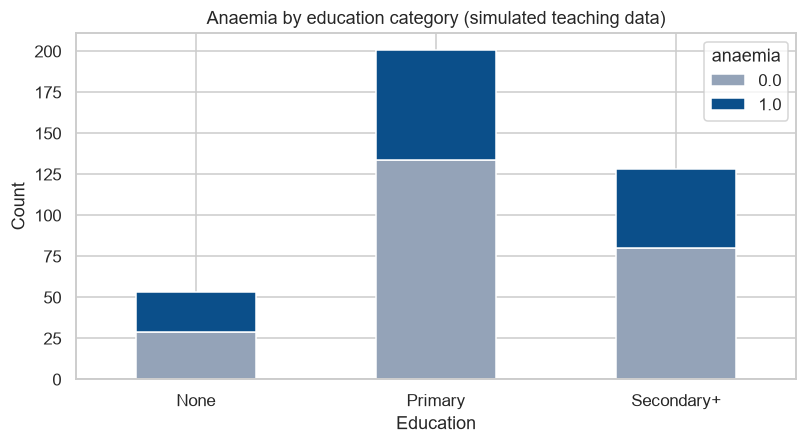

Observed counts:
anaemia     0.0  1.0
education           
None         29   24
Primary     134   67
Secondary+   80   48

Row percentages:
anaemia      0.0   1.0
education             
None        54.7  45.3
Primary     66.7  33.3
Secondary+  62.5  37.5

Column percentages:
anaemia      0.0   1.0
education             
None        11.9  17.3
Primary     55.1  48.2
Secondary+  32.9  34.5

Expected counts:
anaemia        0.0    1.0
education                
None         33.71  19.29
Primary     127.86  73.14
Secondary+   81.42  46.58

Chi-square = 2.6903, df = 2, p = 0.2605
Minimum expected count = 19.29


{'observed': {'0.0': {'None': 29, 'Primary': 134, 'Secondary+': 80},
  '1.0': {'None': 24, 'Primary': 67, 'Secondary+': 48}},
 'row_percent': {'0.0': {'None': 54.717,
   'Primary': 66.667,
   'Secondary+': 62.5},
  '1.0': {'None': 45.283, 'Primary': 33.333, 'Secondary+': 37.5}},
 'column_percent': {'0.0': {'None': 11.934,
   'Primary': 55.144,
   'Secondary+': 32.922},
  '1.0': {'None': 17.266, 'Primary': 48.201, 'Secondary+': 34.532}},
 'expected': [[33.71465968586387, 19.285340314136125],
  [127.86125654450262, 73.13874345549738],
  [81.42408376963351, 46.575916230366495]],
 'chi2': 2.6903026379269273,
 'df': 2,
 'p': 0.26050028624413535,
 'min_expected': 19.285340314136125,
 'monte_carlo_p': None}

In [20]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

edu_order = ["None", "Primary", "Secondary+"]
edu = anc.dropna(subset=["education", "anaemia"]).copy()
edu["education"] = pd.Categorical(edu["education"], categories=edu_order, ordered=True)
observed = pd.crosstab(edu["education"], edu["anaemia"])
row_pct = pd.crosstab(edu["education"], edu["anaemia"], normalize="index") * 100
col_pct = pd.crosstab(edu["education"], edu["anaemia"], normalize="columns") * 100
chi2, chi_p, chi_df, expected = st.chi2_contingency(observed)
min_expected = float(expected.min())

# Deterministic Monte Carlo alternative, used only if expected counts are inadequate.
mc_p = None
if min_expected < 5:
    rng = np.random.default_rng(20261122)
    labels = np.repeat(edu["education"].astype(str).to_numpy(), 1)
    outcomes = edu["anaemia"].astype(int).to_numpy()
    statistic = chi2
    exceed = 0
    replicates = 10000
    for _ in range(replicates):
        permuted = rng.permutation(outcomes)
        simulated = pd.crosstab(labels, permuted)
        sim_stat = st.chi2_contingency(simulated)[0]
        exceed += int(sim_stat >= statistic)
    mc_p = (exceed + 1) / (replicates + 1)

observed.plot(kind="bar", stacked=True, figsize=(7.5, 4.2), color=["#94a3b8", "#0b4f8a"])
plt.title("Anaemia by education category (simulated teaching data)")
plt.xlabel("Education")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
plt.close("all")

print("Observed counts:")
print(observed.to_string())
print("\nRow percentages:")
print(row_pct.round(1).to_string())
print("\nColumn percentages:")
print(col_pct.round(1).to_string())
print("\nExpected counts:")
print(pd.DataFrame(expected, index=observed.index,
                   columns=observed.columns).round(2).to_string())
print(f"\nChi-square = {chi2:.4f}, df = {chi_df}, p = {chi_p:.4g}")
print(f"Minimum expected count = {min_expected:.2f}")
if mc_p is not None:
    print(f"Monte Carlo permutation p = {mc_p:.4g}")
record("Q7a", {
    "observed": observed.to_dict(),
    "row_percent": row_pct.round(3).to_dict(),
    "column_percent": col_pct.round(3).to_dict(),
    "expected": expected.tolist(),
    "chi2": float(chi2), "df": int(chi_df), "p": float(chi_p),
    "min_expected": min_expected,
    "monte_carlo_p": mc_p,
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q7b — Anaemia prevalence versus 30%

**Practical requirement.** Test whether observed anaemia prevalence differs from a hypothesised 30%.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Compare one observed proportion with a specified null value.
- Statistical concept: An exact binomial test is appropriate when counts are modest or approximation assumptions are uncertain.
- Do you need to write code? Yes — one proportion-test cell.
- What to do in Jupyter: Run Q7(b) and state the hypotheses before reading the output.
- Code to use: Use the verified Q7(b) code cell.
- Output to inspect: Observed proportion, null value, exact p-value and 95% Wilson CI.
- Important values or observations: Whether 0.30 lies inside the interval and the exact p-value.
- How to interpret it: The test concerns the simulated cohort's underlying proportion, not a real population guideline.
- What to report: Report H0/H1, x/n, p-value, CI and a contextual conclusion.
- Common mistakes to avoid: Using an inappropriate normal approximation without checking expected counts.

**Output to inspect.** Exact binomial p-value and Wilson CI.

**Interpretation guidance.** If the null value lies outside the interval, the two-sided test will typically be significant.

**Reporting guidance.** Report the test and interval together with the direction of the difference.

**Worked report from the executed notebook.** Against the null prevalence 0.30, the observed 139/382 = 0.3639 gave an exact binomial p=0.0073; the 95% Wilson interval was 31.72% to 41.33%, which excludes the null. 18 records with missing anaemia were excluded.

*Verified source:* Q7b output and dataset audit · anc_cohort.csv. *Teaching note:* State H0, the evaluable denominator, the exact test and the interval together. The null value is a teaching hypothesis, not a clinical guideline.

**Common mistakes.** Forgetting to state the null hypothesis or using the wrong denominator.


**Code cell `q7b`**

In [21]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

anaemia_complete = anc["anaemia"].dropna().astype(int)
x = int(anaemia_complete.sum())
n = int(anaemia_complete.size)
p_hat = x / n
exact = st.binomtest(x, n, p=0.30, alternative="two-sided")
wilson = proportion_confint(x, n, alpha=0.05, method="wilson")
print(f"Observed proportion = {x}/{n} = {p_hat:.4f}")
print(f"Null proportion = 0.30")
print(f"Exact binomial p = {exact.pvalue:.4g}")
print(f"Wilson 95% CI = [{wilson[0]:.4f}, {wilson[1]:.4f}]")
record("Q7b", {
    "x": x, "n": n, "p_hat": float(p_hat), "null_p": 0.30,
    "exact_p": float(exact.pvalue),
    "ci": [float(wilson[0]), float(wilson[1])],
})


Observed proportion = 139/382 = 0.3639
Null proportion = 0.30
Exact binomial p = 0.007323
Wilson 95% CI = [0.3172, 0.4133]


{'x': 139,
 'n': 382,
 'p_hat': 0.36387434554973824,
 'null_p': 0.3,
 'exact_p': 0.007322830837467615,
 'ci': [0.3172050127096916, 0.4132542274199954]}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q7c — Preterm proportions by anaemia

**Practical requirement.** Compare preterm delivery proportions between anaemic and non-anaemic women.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Compare two independent proportions and quantify the difference.
- Statistical concept: A two-proportion z test assesses the difference; an interval describes its plausible size.
- Do you need to write code? Yes — one two-proportion cell.
- What to do in Jupyter: Run Q7(c) and read the group table, difference, CI and p-values.
- Code to use: Use the verified Q7(c) code cell.
- Output to inspect: Group counts/denominators/proportions, risk difference, Newcombe CI, z test and Fisher exact p.
- Important values or observations: The size and direction of the difference and consistency between tests.
- How to interpret it: This is an observational association; anaemia is not randomly assigned.
- What to report: Report both group proportions, the difference with CI and the p-value.
- Common mistakes to avoid: Interpreting association as causation or omitting denominators.

**Output to inspect.** Group table, difference, CI and p-values.

**Interpretation guidance.** A positive difference means preterm was more common in the anaemia group in this sample.

**Reporting guidance.** Use the proportion-test template and add a non-causal interpretation.

**Worked report from the executed notebook.** Preterm delivery occurred in Anaemia 25/139 (17.99%) and No anaemia 22/243 (9.05%), a risk difference of 8.93% (95% CI 1.97% to 16.75%; z=2.56, p=0.0106; Fisher p=0.0146). This is an unadjusted association in simulated data.

*Verified source:* Q7c output · anc_cohort.csv. *Teaching note:* Both the large-sample test and Fisher's exact test address the same table. Do not phrase the difference as anaemia causing preterm delivery.

**Common mistakes.** Saying anaemia caused preterm delivery.


**Code cell `q7c`**

In [22]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

sub = anc.dropna(subset=["anaemia"]).copy()
sub["anaemia"] = sub["anaemia"].astype(int)
exposed = sub.loc[sub["anaemia"] == 1, "preterm"]
unexposed = sub.loc[sub["anaemia"] == 0, "preterm"]
x1, n1 = int(exposed.sum()), int(exposed.size)
x0, n0 = int(unexposed.sum()), int(unexposed.size)
p1, p0 = x1 / n1, x0 / n0
z_stat, z_p = proportions_ztest([x1, x0], [n1, n0])
diff_ci = confint_proportions_2indep(
    x1, n1, x0, n0, compare="diff", method="newcomb"
)
fisher = st.fisher_exact([[x1, n1 - x1], [x0, n0 - x0]])
table = pd.DataFrame({
    "group": ["Anaemia", "No anaemia"],
    "preterm_events": [x1, x0],
    "denominator": [n1, n0],
    "proportion": [p1, p0],
})
print(table.to_string(index=False, formatters={"proportion": lambda v: f"{v:.4f}"}))
print(f"Difference = {p1 - p0:+.4f}")
print(f"Newcombe 95% CI = [{diff_ci[0]:.4f}, {diff_ci[1]:.4f}]")
print(f"Two-proportion z = {z_stat:.4f}, p = {z_p:.4g}")
print(f"Fisher exact p = {fisher.pvalue:.4g}")
record("Q7c", {
    "groups": table.to_dict(orient="records"),
    "difference": float(p1 - p0),
    "ci": [float(diff_ci[0]), float(diff_ci[1])],
    "z": float(z_stat), "z_p": float(z_p), "fisher_p": float(fisher.pvalue),
})


     group  preterm_events  denominator proportion
   Anaemia              25          139     0.1799
No anaemia              22          243     0.0905
Difference = +0.0893
Newcombe 95% CI = [0.0197, 0.1675]
Two-proportion z = 2.5570, p = 0.01056
Fisher exact p = 0.01459


{'groups': [{'group': 'Anaemia',
   'preterm_events': 25,
   'denominator': 139,
   'proportion': 0.17985611510791366},
  {'group': 'No anaemia',
   'preterm_events': 22,
   'denominator': 243,
   'proportion': 0.09053497942386832}],
 'difference': 0.08932113568404534,
 'ci': [0.01970387633946194, 0.16748155119074942],
 'z': 2.556966994840861,
 'z_p': 0.010558923544111731,
 'fisher_p': 0.014594044167015211}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [23]:
mark_done("Q7")

Progress: ■■■■■■■□□□  7/10 questions covered


<a id="q8"></a>

## Q8. Linear regression

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q8a | Fit birthweight ~ gest_age and interpret slope, intercept and R-squared. | Mixed | Run Q8(a), inspect the coefficient table and regression plot. | See code cell q8a | Coefficient table, R-squared and plot. | A one-week increase in gestational age is associated with about the fitted slope increase in mean birthweight. | Report the slope in grams per week with CI and p-value. |
| Q8b | Fit birthweight ~ gest_age + bmi + iptp3 + anc_visits with categorical handling. | Mixed | Run Q8(b), inspect complete-case size and adjusted coefficients. | See code cell q8b | Adjusted coefficient table and model fit statistics. | Conditional on the other predictors, each coefficient describes the associated change in mean birthweight. | Use the regression template with explicit reference levels. |
| Q8c | Assess linearity, residual normality, homoscedasticity, independence and influence. | Mixed | Run Q8(b), then Q8(c), and interpret each of the four diagnostic panels. | See code cell q8c | Four plots plus numeric influence summary. | Diagnostics guide model trustworthiness and possible refinement; they are not mechanical pass/fail tests. | Describe each plot briefly and state any limitation. |
| Q8d | Extend the regression with facility_type and compare nested models. | Mixed | Run Q8(b), then Q8(d), and compare the F test, AIC and adjusted R-squared on the same complete cases. | See code cell q8d | Nested F test, AIC and adjusted R-squared. | A small p-value suggests the added facility terms explain extra variation in this sample. | Report F, df, p, AIC difference and adjusted R-squared difference. |
| Q8e | Predict birthweight for BMI=22, ANC=5, IPTp3=Yes, gest_age=39 and explain interval types. | Calculation | Run Q8(b) and Q8(d), then Q8(e), and compare the mean-response CI with the individual prediction interval. | See code cell q8e | Prediction table for both models. | The prediction interval is wider because it adds uncertainty for a new individual observation. | Report the point prediction, mean CI and individual PI with the model used. |


#### Q8a — Simple linear regression

**Practical requirement.** Fit birthweight ~ gest_age and interpret slope, intercept and R-squared.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Model birthweight as a linear function of gestational age.
- Statistical concept: Simple linear regression estimates an average change in the outcome per one-unit change in the predictor.
- Do you need to write code? Yes — one model-and-plot cell.
- What to do in Jupyter: Run Q8(a), then read the scatterplot before the coefficient table.
- Code to use: Use the verified Q8(a) code cell.
- Output to inspect: Coefficients with SEs, CIs and p-values, R-squared and a fitted-line plot.
- Important values or observations: The gest_age slope, its CI and R-squared.
- How to interpret it: The slope is an average association, not a causal effect.
- What to report: Report the fitted equation, slope with CI/p and R-squared.
- Common mistakes to avoid: Interpreting the intercept outside the observed range or treating R-squared as causation.

**Output to inspect.** Coefficient table, R-squared and plot.

**Interpretation guidance.** A one-week increase in gestational age is associated with about the fitted slope increase in mean birthweight.

**Reporting guidance.** Report the slope in grams per week with CI and p-value.

**Worked report from the executed notebook.** In the simple linear model, each additional week of gestational age was associated with 65.64 g higher mean birthweight (95% CI 49.13 to 82.16, p<0.0001); n=400 and R-squared=0.133. The intercept (515.69 g at zero weeks) is outside the observed range.

*Verified source:* Q8a output · anc_cohort.csv. *Teaching note:* Interpret the slope in grams per week with its interval. R-squared describes explained variation, not causation or individual prediction accuracy.

**Common mistakes.** Extrapolating to gestational age zero or claiming causality.


**Code cell `q8a`**

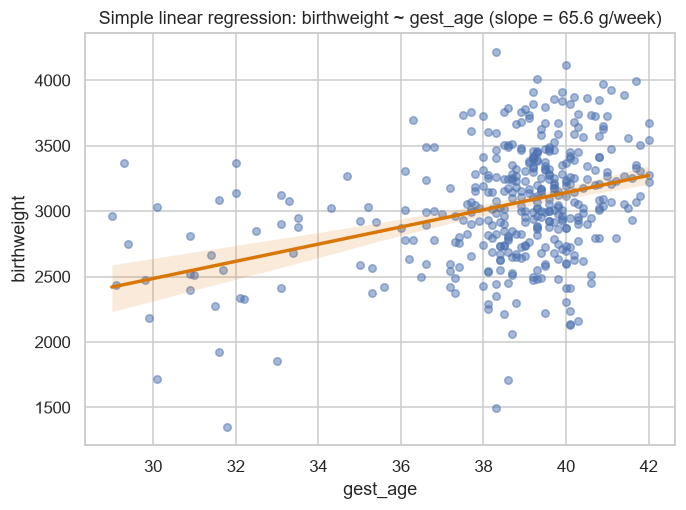

     term  coefficient  std_error  ci_low  ci_high    p_value
Intercept       515.69     324.58 -122.41   1153.8     0.1129
 gest_age       65.644     8.4005  49.129   82.159 4.9809e-14
R-squared = 0.1330; n = 400


{'terms': [{'term': 'Intercept',
   'coefficient': 515.6909632305628,
   'std_error': 324.57855366427475,
   'ci_low': -122.41175287303668,
   'ci_high': 1153.7936793341623,
   'p_value': 0.11289920188664387},
  {'term': 'gest_age',
   'coefficient': 65.64361897495274,
   'std_error': 8.40053837032518,
   'ci_low': 49.128645048543866,
   'ci_high': 82.15859290136163,
   'p_value': 4.9808701391472734e-14}],
 'r_squared': 0.13301465083528163,
 'n': 400}

In [24]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

model_simple = smf.ols("birthweight ~ gest_age", data=anc).fit()
simple_ci = model_simple.conf_int()
simple_terms = pd.DataFrame({
    "term": model_simple.params.index,
    "coefficient": model_simple.params.values,
    "std_error": model_simple.bse.values,
    "ci_low": simple_ci.iloc[:, 0].values,
    "ci_high": simple_ci.iloc[:, 1].values,
    "p_value": model_simple.pvalues.values,
})
sns.regplot(data=anc, x="gest_age", y="birthweight",
            scatter_kws={"alpha": 0.5, "s": 24},
            line_kws={"color": "#d97706"})
plt.title(f"Simple linear regression: birthweight ~ gest_age "
          f"(slope = {model_simple.params['gest_age']:.1f} g/week)")
plt.tight_layout()
plt.show()
plt.close("all")
print(simple_terms.to_string(index=False, float_format=lambda v: f"{v:.5g}"))
print(f"R-squared = {model_simple.rsquared:.4f}; n = {int(model_simple.nobs)}")
record("Q8a", {
    "terms": simple_terms.to_dict(orient="records"),
    "r_squared": float(model_simple.rsquared), "n": int(model_simple.nobs),
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q8b — Multiple linear regression

**Practical requirement.** Fit birthweight ~ gest_age + bmi + iptp3 + anc_visits with categorical handling.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Estimate adjusted associations with several predictors.
- Statistical concept: Multiple regression estimates each coefficient conditional on the other predictors in the model.
- Do you need to write code? Yes — one model cell.
- What to do in Jupyter: Run Q8(b) and note the complete-case n after BMI missingness.
- Code to use: Use the verified Q8(b) code cell.
- Output to inspect: Adjusted coefficient table with SEs, CIs and p-values, plus R-squared and adjusted R-squared.
- Important values or observations: Adjusted coefficients, especially the IPTp3 term and the reduction in n.
- How to interpret it: Adjusted coefficients answer a different question from crude group differences.
- What to report: Report each adjusted coefficient with CI/p and the complete-case denominator.
- Common mistakes to avoid: Comparing models fitted on different samples without saying so.

**Output to inspect.** Adjusted coefficient table and model fit statistics.

**Interpretation guidance.** Conditional on the other predictors, each coefficient describes the associated change in mean birthweight.

**Reporting guidance.** Use the regression template with explicit reference levels.

**Worked report from the executed notebook.** In the adjusted model (n=390 after excluding 10 records with missing BMI), estimated mean birthweight differences were IPTp3 Yes versus No: 177.16 g (95% CI 94.46 to 259.86, p<0.0001); per additional week of gestational age: 57.40 g (95% CI 40.77 to 74.03, p<0.0001); per unit of BMI: 12.16 g (95% CI 1.76 to 22.55, p=0.0220); per additional ANC visit: 23.62 g (95% CI 2.46 to 44.77, p=0.0287). R-squared=0.183 and adjusted R-squared=0.174.

*Verified source:* Q8b output · anc_cohort.csv. *Teaching note:* Name the reference level 'IPTp3 No' and the complete-case denominator. Coefficients are conditional associations from observational data.

**Common mistakes.** Forgetting which category is the reference or ignoring missing-data exclusions.


**Code cell `q8b`**

In [25]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

anc_model = anc.dropna(subset=["bmi"]).copy()
formula_base = (
    "birthweight ~ gest_age + bmi + "
    "C(iptp3, Treatment(reference='No')) + anc_visits"
)
model_multi = smf.ols(formula_base, data=anc_model).fit()
multi_ci = model_multi.conf_int()
multi_terms = pd.DataFrame({
    "term": model_multi.params.index,
    "coefficient": model_multi.params.values,
    "std_error": model_multi.bse.values,
    "ci_low": multi_ci.iloc[:, 0].values,
    "ci_high": multi_ci.iloc[:, 1].values,
    "p_value": model_multi.pvalues.values,
})
print(multi_terms.to_string(index=False, float_format=lambda v: f"{v:.5g}"))
print(f"R-squared = {model_multi.rsquared:.4f}, "
      f"adjusted R-squared = {model_multi.rsquared_adj:.4f}, "
      f"n = {int(model_multi.nobs)}")
print("Records excluded for missing BMI:", int(anc["bmi"].isna().sum()))
record("Q8b", {
    "terms": multi_terms.to_dict(orient="records"),
    "r_squared": float(model_multi.rsquared),
    "adj_r_squared": float(model_multi.rsquared_adj),
    "n": int(model_multi.nobs),
    "missing_bmi_excluded": int(anc["bmi"].isna().sum()),
})


                                      term  coefficient  std_error  ci_low  ci_high    p_value
                                 Intercept       329.61      343.8 -346.35   1005.6     0.3383
C(iptp3, Treatment(reference='No'))[T.Yes]       177.16     42.063  94.455   259.86 3.1594e-05
                                  gest_age       57.398     8.4587  40.767   74.029 4.3763e-11
                                       bmi       12.158     5.2864  1.7642   22.552   0.021989
                                anc_visits       23.615     10.758  2.4638   44.766   0.028747
R-squared = 0.1828, adjusted R-squared = 0.1743, n = 390
Records excluded for missing BMI: 10


{'terms': [{'term': 'Intercept',
   'coefficient': 329.6066308152863,
   'std_error': 343.79795672550966,
   'ci_low': -346.34993915403913,
   'ci_high': 1005.5632007846117,
   'p_value': 0.338300528725051},
  {'term': "C(iptp3, Treatment(reference='No'))[T.Yes]",
   'coefficient': 177.15826776025577,
   'std_error': 42.063455683875276,
   'ci_low': 94.45542247304486,
   'ci_high': 259.8611130474667,
   'p_value': 3.159423498616959e-05},
  {'term': 'gest_age',
   'coefficient': 57.398301745063876,
   'std_error': 8.458710284070843,
   'ci_low': 40.767252379782605,
   'ci_high': 74.02935111034515,
   'p_value': 4.3762912311256736e-11},
  {'term': 'bmi',
   'coefficient': 12.15804713358686,
   'std_error': 5.286388754165395,
   'ci_low': 1.7642412953425843,
   'ci_high': 22.55185297183114,
   'p_value': 0.02198943548829969},
  {'term': 'anc_visits',
   'coefficient': 23.61516258423454,
   'std_error': 10.75776510490491,
   'ci_low': 2.463838503931594,
   'ci_high': 44.76648666453748,
   

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q8c — Linear regression diagnostics

**Practical requirement.** Assess linearity, residual normality, homoscedasticity, independence and influence.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Check whether the regression model's assumptions are plausible.
- Statistical concept: Residual plots reveal non-linearity and unequal spread; Q-Q plots assess normality; influence measures find influential records.
- Do you need to write code? Yes — one diagnostic plotting cell.
- What to do in Jupyter: Run Q8(b), then Q8(c), and examine each panel rather than only the Durbin-Watson number.
- Code to use: Use the verified Q8(c) code cell.
- Output to inspect: Four diagnostic plots, Durbin-Watson, Cook's D threshold and top influential rows.
- Important values or observations: Pattern in residuals vs fitted, Q-Q departures, funnel shapes and large Cook's D values.
- How to interpret it: Independence is mainly justified by the study design here because each id is one woman.
- What to report: Report what each plot assesses and whether any concern is visible.
- Common mistakes to avoid: Declaring assumptions 'passed' from one plot, or deleting influential points solely because they are influential.

**Output to inspect.** Four plots plus numeric influence summary.

**Interpretation guidance.** Diagnostics guide model trustworthiness and possible refinement; they are not mechanical pass/fail tests.

**Reporting guidance.** Describe each plot briefly and state any limitation.

**Worked report from the executed notebook.** For the Q8b model, Durbin-Watson=1.99 is descriptive only because ANC rows have no meaningful time order; independence rests on one row per woman and the study design. The largest Cook's distance was 0.049 at row index 243 against a 4/n screening threshold of 0.0103. The residual-versus-fitted, scale-location, Q-Q and influence plots must also be described in words because the numbers alone do not check linearity or normality.

*Verified source:* Q8c output · anc_cohort.csv. *Teaching note:* Cook's distance is a screen, not an automatic deletion rule. State what each plot shows and justify any decision about influential records.

**Common mistakes.** Treating a single high Cook's D as automatic proof of an error.


**Code cell `q8c`**

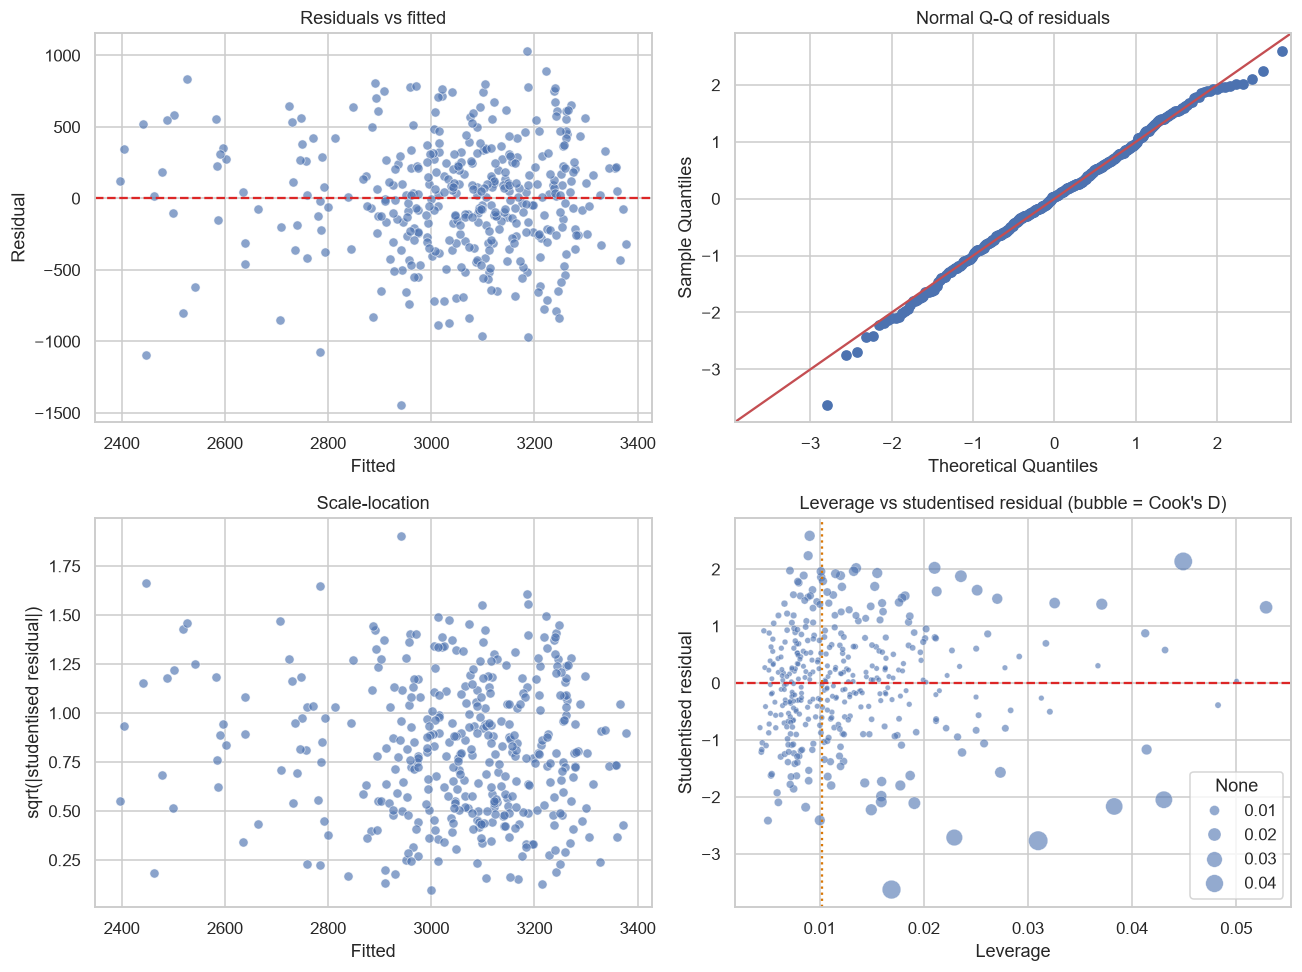

Durbin-Watson statistic = 1.9872 (descriptive only: ANC rows have no meaningful time order)
Cook's D warning threshold 4/n = 0.01026
Largest Cook's D values (row index, value):
243    0.04901
365    0.04524
399    0.04294
158    0.03776
100    0.03737


{'durbin_watson': 1.9872089311707541,
 'cooks_threshold': 0.010256410256410256,
 'top_cooks': [{'row_index': '243', 'cooks_d': 0.049014111917957105},
  {'row_index': '365', 'cooks_d': 0.04523631658678923},
  {'row_index': '399', 'cooks_d': 0.042943720420679954},
  {'row_index': '158', 'cooks_d': 0.037755383131797715},
  {'row_index': '100', 'cooks_d': 0.037373246208354964}]}

In [26]:
_required_cells = ('q8b',)
_required_names = ('model_multi', 'anc_model')
_missing = [name for name in _required_names if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run prerequisite code cell(s) " + ", ".join(_required_cells)
        + " before this cell. Missing objects: " + ", ".join(_missing)
    )

# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

influence = model_multi.get_influence()
fitted = model_multi.fittedvalues
residuals = model_multi.resid
student_resid = influence.resid_studentized_internal
leverage = influence.hat_matrix_diag
# Cook's distance is positional in the fitted model; use the model's own
# row labels so any rows dropped by the formula are handled correctly.
cooks = pd.Series(influence.cooks_distance[0], index=fitted.index)
top_influential = cooks.sort_values(ascending=False).head(5)
threshold = 4 / int(model_multi.nobs)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.scatterplot(x=fitted, y=residuals, alpha=0.65, ax=axes[0, 0])
axes[0, 0].axhline(0, color="#dc2626", linestyle="--")
axes[0, 0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
sm.qqplot(residuals, line="45", fit=True, ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q of residuals")
sns.scatterplot(x=fitted, y=np.sqrt(np.abs(student_resid)), alpha=0.65, ax=axes[1, 0])
axes[1, 0].set(title="Scale-location", xlabel="Fitted",
               ylabel="sqrt(|studentised residual|)")
sns.scatterplot(x=leverage, y=student_resid, size=cooks, sizes=(12, 160),
                alpha=0.6, ax=axes[1, 1])
axes[1, 1].axhline(0, color="#dc2626", linestyle="--")
axes[1, 1].axvline(threshold, color="#d97706", linestyle=":")
axes[1, 1].set(title="Leverage vs studentised residual (bubble = Cook's D)",
               xlabel="Leverage", ylabel="Studentised residual")
plt.tight_layout()
plt.show()
plt.close("all")

print(f"Durbin-Watson statistic = {durbin_watson(residuals):.4f} "
      "(descriptive only: ANC rows have no meaningful time order)")
print(f"Cook's D warning threshold 4/n = {threshold:.5f}")
print("Largest Cook's D values (row index, value):")
print(top_influential.round(5).to_string())
record("Q8c", {
    "durbin_watson": float(durbin_watson(residuals)),
    "cooks_threshold": float(threshold),
    "top_cooks": [
        {"row_index": str(index), "cooks_d": float(value)}
        for index, value in top_influential.items()
    ],
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q8d — Add facility type

**Practical requirement.** Extend the regression with facility_type and compare nested models.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Assess whether facility type improves the model after the existing predictors.
- Statistical concept: Nested-model comparison tests whether the added block explains additional variation beyond the base model.
- Do you need to write code? Yes — one model-comparison cell.
- What to do in Jupyter: Run Q8(b), then Q8(d), and confirm both models used the same complete-case sample.
- Code to use: Use the verified Q8(d) code cell.
- Output to inspect: Nested F test, AIC, adjusted R-squared and complete-case n.
- Important values or observations: The block p-value, AIC change and whether adjusted R-squared improves.
- How to interpret it: A better fit does not establish a causal facility effect.
- What to report: Report the comparison statistics and state whether facility type adds explanatory value.
- Common mistakes to avoid: Comparing AIC across different samples or ignoring model complexity.

**Output to inspect.** Nested F test, AIC and adjusted R-squared.

**Interpretation guidance.** A small p-value suggests the added facility terms explain extra variation in this sample.

**Reporting guidance.** Report F, df, p, AIC difference and adjusted R-squared difference.

**Worked report from the executed notebook.** Adding facility type to the Q8b model gives mixed, weak evidence of improvement on the same complete cases (n=390): nested F with 2 numerator degrees of freedom=1.84, p=0.1594; AIC 5,787.02 versus 5,786.76 (change 0.26); adjusted R-squared 0.178 versus 0.174 (change 0.004).

*Verified source:* Q8d output · anc_cohort.csv. *Teaching note:* Compare nested models only on the same sample, and weigh the block test, AIC and complexity together. A better fit is not a causal facility effect.

**Common mistakes.** Claiming the facility coefficient is causal.


**Code cell `q8d`**

In [27]:
_required_cells = ('q8b',)
_required_names = ('model_multi', 'anc_model', 'formula_base')
_missing = [name for name in _required_names if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run prerequisite code cell(s) " + ", ".join(_required_cells)
        + " before this cell. Missing objects: " + ", ".join(_missing)
    )

# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

formula_extended = formula_base + (
    " + C(facility_type, Treatment(reference='Urban'))"
)
model_extended = smf.ols(formula_extended, data=anc_model).fit()
anova_models = sm.stats.anova_lm(model_multi, model_extended)
print("Nested-model comparison (base vs + facility_type):")
print(anova_models.to_string(float_format=lambda v: f"{v:.6g}"))
print(f"AIC base = {model_multi.aic:.2f}")
print(f"AIC extended = {model_extended.aic:.2f}")
print(f"Adjusted R2 base = {model_multi.rsquared_adj:.4f}")
print(f"Adjusted R2 extended = {model_extended.rsquared_adj:.4f}")
print(f"Complete-case n used for both models = {int(model_multi.nobs)}")
record("Q8d", {
    "f_statistic": float(anova_models.loc[1, "F"]),
    "p_value": float(anova_models.loc[1, "Pr(>F)"]),
    "df_diff": int(anova_models.loc[1, "df_diff"]),
    "aic_base": float(model_multi.aic),
    "aic_extended": float(model_extended.aic),
    "adj_r2_base": float(model_multi.rsquared_adj),
    "adj_r2_extended": float(model_extended.rsquared_adj),
    "n": int(model_multi.nobs),
})


Nested-model comparison (base vs + facility_type):
   df_resid         ssr  df_diff  ss_diff       F   Pr(>F)
0       385 6.18655e+07        0      NaN     NaN      NaN
1       383 6.12752e+07        2   590309 1.84486 0.159449
AIC base = 5786.76
AIC extended = 5787.02
Adjusted R2 base = 0.1743
Adjusted R2 extended = 0.1779
Complete-case n used for both models = 390


{'f_statistic': 1.8448598154298994,
 'p_value': 0.15944917874152495,
 'df_diff': 2,
 'aic_base': 5786.759247579495,
 'aic_extended': 5787.02007413781,
 'adj_r2_base': 0.17431518509382127,
 'adj_r2_extended': 0.17792318336691115,
 'n': 390}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q8e — Prediction with intervals

**Practical requirement.** Predict birthweight for BMI=22, ANC=5, IPTp3=Yes, gest_age=39 and explain interval types.
**Task classification.** Calculation
**Code required.** Yes

**Learning guide**

- What is being asked? Use a fitted model to predict and distinguish two interval types.
- Statistical concept: A confidence interval targets the mean response; a prediction interval includes individual residual variability.
- Do you need to write code? Yes — one prediction cell.
- What to do in Jupyter: Run Q8(b) and Q8(d), then Q8(e), and note which model and facility assumption each prediction uses.
- Code to use: Use the verified Q8(e) code cell.
- Output to inspect: Predicted mean with 95% CI and 95% prediction interval for an individual.
- Important values or observations: The prediction interval must be wider than the mean-response CI.
- How to interpret it: Predictions are model-based estimates for a hypothetical profile, not observed data.
- What to report: Report the fitted model, covariates, prediction and both intervals.
- Common mistakes to avoid: Confusing the two interval types or omitting the facility assumption when using the extended model.

**Output to inspect.** Prediction table for both models.

**Interpretation guidance.** The prediction interval is wider because it adds uncertainty for a new individual observation.

**Reporting guidance.** Report the point prediction, mean CI and individual PI with the model used.

**Worked report from the executed notebook.** For the hypothetical profile (gest_age 39 weeks, BMI 22, IPTp3 Yes, 5 ANC visits), the base model predicted mean birthweight 3,130.85 g (95% CI 3,078.57 to 3,183.13) and an individual prediction interval 2,340.97 to 3,920.73 g. With facility type added and Urban specified, the corresponding values were 3,175.03 g (mean CI 3,102.69 to 3,247.38) and 2,385.27 to 3,964.79 g.

*Verified source:* Q8e output · anc_cohort.csv. *Teaching note:* A prediction interval is wider than the mean-response interval because it includes residual variation for one new observation. State which model generated each number.

**Common mistakes.** Calling the prediction interval a confidence interval for the mean.


**Code cell `q8e`**

In [28]:
_required_cells = ('q8b', 'q8d')
_required_names = ('model_multi', 'model_extended')
_missing = [name for name in _required_names if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run prerequisite code cell(s) " + ", ".join(_required_cells)
        + " before this cell. Missing objects: " + ", ".join(_missing)
    )

# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

hypothetical = pd.DataFrame({
    "gest_age": [39.0], "bmi": [22.0], "iptp3": ["Yes"], "anc_visits": [5],
})
prediction = model_multi.get_prediction(hypothetical).summary_frame(alpha=0.05)
hypothetical_with_facility = hypothetical.copy()
hypothetical_with_facility["facility_type"] = "Urban"
prediction_urban = model_extended.get_prediction(
    hypothetical_with_facility
).summary_frame(alpha=0.05)
print("Model without facility type (Q8b):")
print(prediction.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nModel with facility type, assuming Urban (Q8d):")
print(prediction_urban.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
record("Q8e", {
    "model_without_facility": prediction.iloc[0].to_dict(),
    "model_with_facility_urban": prediction_urban.iloc[0].to_dict(),
})


Model without facility type (Q8b):
   mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
3130.85    26.59        3078.57        3183.13       2340.97       3920.73

Model with facility type, assuming Urban (Q8d):
   mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
3175.03    36.79        3102.69        3247.38       2385.27       3964.79


{'model_without_facility': {'mean': 3130.851516493117,
  'mean_se': 26.589096480847907,
  'mean_ci_lower': 3078.5735023159496,
  'mean_ci_upper': 3183.129530670284,
  'obs_ci_lower': 2340.968815843883,
  'obs_ci_upper': 3920.7342171423506},
 'model_with_facility_urban': {'mean': 3175.033131939952,
  'mean_se': 36.79361969227149,
  'mean_ci_lower': 3102.6903561212857,
  'mean_ci_upper': 3247.3759077586183,
  'obs_ci_lower': 2385.2729431910484,
  'obs_ci_upper': 3964.7933206888556}}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [29]:
mark_done("Q8")

Progress: ■■■■■■■■□□  8/10 questions covered


<a id="q9"></a>

## Q9. Logistic regression

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q9 | Fit preterm ~ age + anaemia + anc_visits, report odds ratios and model-based predictions. | Mixed | Run Q9, inspect coefficients/odds ratios, scenario probabilities and the prediction plot. | See code cell q9 | Coefficient/OR table, scenario probabilities and plot. | An OR above 1 means higher odds of preterm for the exposed group at fixed age and ANC visits. | Use the logistic template and explicitly compare odds with probability. |


#### Q9 — Logistic regression

**Practical requirement.** Fit preterm ~ age + anaemia + anc_visits, report odds ratios and model-based predictions.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Model a binary outcome and interpret adjusted odds ratios.
- Statistical concept: Logistic regression models the log-odds; exponentiating coefficients gives odds ratios.
- Do you need to write code? Yes — one model and prediction cell.
- What to do in Jupyter: Run Q9 and read the coefficient table before the scenario plot.
- Code to use: Use the verified Q9 code cell.
- Output to inspect: Coefficients, ORs with CIs and p-values, pseudo R-squared, two scenario probabilities and a stratified plot.
- Important values or observations: The anaemia OR and the predicted probabilities for age 25 and ANC 4.
- How to interpret it: Odds ratios are not risk ratios, and the data are observational.
- What to report: Report adjusted ORs with CIs/p, the scenario probabilities and non-causal wording.
- Common mistakes to avoid: Calling an odds ratio a risk ratio or converting it directly into a probability change.

**Output to inspect.** Coefficient/OR table, scenario probabilities and plot.

**Interpretation guidance.** An OR above 1 means higher odds of preterm for the exposed group at fixed age and ANC visits.

**Reporting guidance.** Use the logistic template and explicitly compare odds with probability.

**Worked report from the executed notebook.** In the logistic model for the recorded preterm flag (n=382), adjusted odds ratios were anaemia OR 2.200 (95% CI 1.183 to 4.093, p=0.0127); each additional ANC visit OR 0.833 (95% CI 0.700 to 0.990, p=0.0385); each additional year of age OR 0.998 (95% CI 0.946 to 1.051, p=0.9274). Pseudo R-squared=0.038. At age 25 with 4 ANC visits, predicted preterm probability was 20.90% with anaemia versus 10.72% without.

*Verified source:* Q9 output · anc_cohort.csv. *Teaching note:* An odds ratio is not a risk ratio. The scenario probabilities translate the log-odds model back to the probability scale for teaching; they are not causal contrasts.

**Common mistakes.** Ignoring the 18 missing anaemia records or saying OR=2 means double the risk.


**Code cell `q9`**

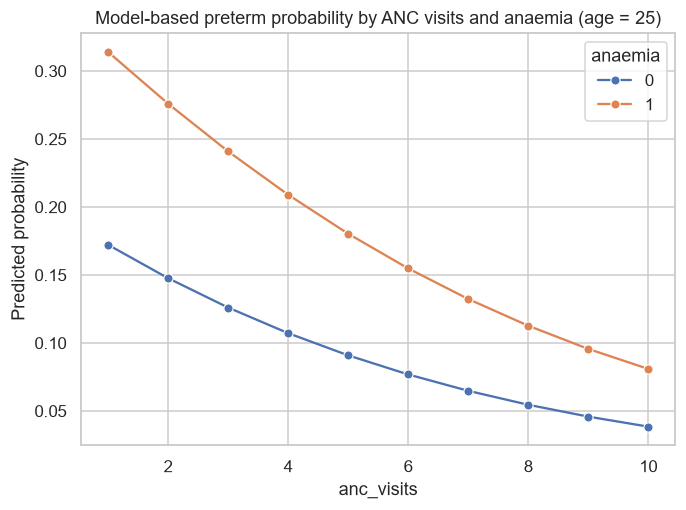

      term  coefficient  std_error  odds_ratio  or_ci_low  or_ci_high  p_value
 Intercept      -1.3255    0.88115     0.26568   0.047242      1.4942  0.13252
       age   -0.0024444   0.026822     0.99756    0.94647      1.0514  0.92739
   anaemia      0.78867     0.3166      2.2005     1.1831      4.0926 0.012734
anc_visits     -0.18324   0.088566     0.83257    0.69989     0.99039 0.038546
Pseudo R-squared = 0.0380; n = 382
No anaemia: predicted probability = 0.1072
Anaemia: predicted probability = 0.2090


{'terms': [{'term': 'Intercept',
   'coefficient': -1.325450151525042,
   'std_error': 0.8811468202533982,
   'odds_ratio': 0.26568333440816827,
   'or_ci_low': 0.047242272456403715,
   'or_ci_high': 1.4941625479041571,
   'p_value': 0.1325213757901126},
  {'term': 'age',
   'coefficient': -0.0024444422509004226,
   'std_error': 0.02682235561771638,
   'odds_ratio': 0.9975585429651671,
   'or_ci_low': 0.9464706732376077,
   'or_ci_high': 1.0514039946306561,
   'p_value': 0.9273857112802618},
  {'term': 'anaemia',
   'coefficient': 0.7886745683766331,
   'std_error': 0.31659545198173794,
   'odds_ratio': 2.200477909528209,
   'or_ci_low': 1.1831245762541511,
   'or_ci_high': 4.092640054568089,
   'p_value': 0.012734415270477422},
  {'term': 'anc_visits',
   'coefficient': -0.18324236394819335,
   'std_error': 0.0885655017865686,
   'odds_ratio': 0.8325663472154797,
   'or_ci_low': 0.6998931785027265,
   'or_ci_high': 0.9903893105496618,
   'p_value': 0.03854572565879232}],
 'pseudo_r_sq

In [30]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

logit_df = anc.dropna(subset=["anaemia"]).copy()
logit_df["anaemia"] = logit_df["anaemia"].astype(int)
model_logit = smf.logit(
    "preterm ~ age + anaemia + anc_visits", data=logit_df
).fit(disp=False)
logit_ci = model_logit.conf_int()
logit_terms = pd.DataFrame({
    "term": model_logit.params.index,
    "coefficient": model_logit.params.values,
    "std_error": model_logit.bse.values,
    "odds_ratio": np.exp(model_logit.params.values),
    "or_ci_low": np.exp(logit_ci.iloc[:, 0].values),
    "or_ci_high": np.exp(logit_ci.iloc[:, 1].values),
    "p_value": model_logit.pvalues.values,
})
scenarios = pd.DataFrame({
    "age": [25.0, 25.0], "anaemia": [0, 1], "anc_visits": [4.0, 4.0],
})
scenario_probabilities = model_logit.predict(scenarios)

visits_grid = np.arange(1, 11, dtype=float)
curve = pd.DataFrame({
    "anc_visits": np.tile(visits_grid, 2),
    "anaemia": np.repeat([0, 1], visits_grid.size),
    "age": 25.0,
})
curve["predicted_probability"] = model_logit.predict(curve)
sns.lineplot(data=curve, x="anc_visits", y="predicted_probability",
             hue="anaemia", marker="o")
plt.title("Model-based preterm probability by ANC visits and anaemia (age = 25)")
plt.ylabel("Predicted probability")
plt.tight_layout()
plt.show()
plt.close("all")

print(logit_terms.to_string(index=False, float_format=lambda v: f"{v:.5g}"))
print(f"Pseudo R-squared = {model_logit.prsquared:.4f}; n = {int(model_logit.nobs)}")
for label, probability in zip(["No anaemia", "Anaemia"], scenario_probabilities):
    print(f"{label}: predicted probability = {probability:.4f}")
record("Q9", {
    "terms": logit_terms.to_dict(orient="records"),
    "pseudo_r_squared": float(model_logit.prsquared),
    "n": int(model_logit.nobs),
    "scenario_probabilities": {
        "no_anaemia": float(scenario_probabilities.iloc[0]),
        "anaemia": float(scenario_probabilities.iloc[1]),
    },
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [31]:
mark_done("Q9")

Progress: ■■■■■■■■■□  9/10 questions covered


<a id="q10"></a>

## Q10. Survival analysis

### Navigation table

| Question/Subquestion | Practical requirement | Task classification | Jupyter action | Code | Output to inspect | Interpretation guidance | Reporting guidance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Q10a | Describe participants, events, censoring and distinguish follow-up time from survival time. | Mixed | Run Q10(a) and state the event/censoring counts clearly. | See code cell q10a | Counts, censoring proportion and median observed follow-up. | Censored records contribute person-time up to their last known time but no event. | Report the descriptive survival-data summary with careful terminology. |
| Q10b | Estimate the survival curve, CIs, S(90), S(180) and median survival where estimable. | Mixed | Run Q10(b), inspect the step curve, confidence band, risk table and numeric estimates. | See code cell q10b | KM plot, CIs, risk table and numeric survival estimates. | A higher curve means a higher estimated probability of remaining readmission-free to that time. | Use the Kaplan-Meier template with time-specific estimates. |
| Q10c | Compare Kaplan-Meier curves by anaemia status and perform a log-rank test. | Mixed | Run Q10(c), inspect both curves and the log-rank result. | See code cell q10c | Stratified KM plot and log-rank output. | A small p-value suggests different readmission-free survival distributions between groups. | Use the log-rank template and avoid causal wording. |
| Q10d | Estimate the constant-hazard rate from events and person-time. | Mixed | Run Q10(a), then Q10(d), and compare exponential survival with the KM estimates. | See code cell q10d | Person-time, rate, CI and exponential-versus-KM comparison. | A close numerical match at selected times supports descriptive agreement, not proof of constant hazard. | Use the exponential-rate template with the assumption stated. |
| Q10e | Fit readmitted ~ anaemia + delivery_mode + age and interpret adjusted hazard ratios. | Mixed | Run Q10(e), inspect HRs, CIs and p-values with the stated reference levels. | See code cell q10e | Cox coefficient/HR table. | An HR above 1 means a higher instantaneous readmission hazard at fixed covariates. | Use the Cox template with explicit reference levels and non-causal wording. |
| Q10f | Assess proportional hazards using Schoenfeld residual diagnostics. | Mixed | Run Q10(e), then Q10(f), and inspect residual plots and the screening tests. | See code cell q10f | Residual plots and screening-test table. | A time trend suggests the hazard ratio may change over follow-up. | Report the screen, its limitation and possible remedies such as time-varying effects or stratification. |


#### Q10a — Survival data description

**Practical requirement.** Describe participants, events, censoring and distinguish follow-up time from survival time.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Summarise a time-to-event dataset correctly.
- Statistical concept: Censoring means the event was not observed by the end of follow-up for that participant.
- Do you need to write code? Yes — one descriptive cell.
- What to do in Jupyter: Run Q10(a) and separate median observed follow-up from median survival.
- Code to use: Use the verified Q10(a) code cell.
- Output to inspect: Participant count, event count, censored count/proportion and median observed follow-up.
- Important values or observations: 209 events, 291 censored and median observed follow-up of 119 days.
- How to interpret it: Median observed follow-up is not an estimate of the median event-free survival time.
- What to report: Report n, events, censoring proportion and the correct label for follow-up time.
- Common mistakes to avoid: Equating median follow-up with median survival.

**Output to inspect.** Counts, censoring proportion and median observed follow-up.

**Interpretation guidance.** Censored records contribute person-time up to their last known time but no event.

**Reporting guidance.** Report the descriptive survival-data summary with careful terminology.

**Worked report from the executed notebook.** The survival file contains 500 women, with 209 readmission events and 291 censored observations (58.2%). Median observed follow-up was 119 days; that is a property of observation time, not an estimate of median readmission-free survival.

*Verified source:* Q10a output · postpartum_survival.csv. *Teaching note:* Censored women contribute person-time up to their last observed time. Do not treat them as event-free at the end of study.

**Common mistakes.** Treating censored observations as event-free at the end of study.


**Code cell `q10a`**

In [32]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

n_surv = int(surv.shape[0])
events = int(surv["readmitted"].sum())
censored = int(n_surv - events)
censoring_proportion = censored / n_surv
median_follow_up = float(surv["time_days"].median())
print(f"Participants: {n_surv}")
print(f"Readmission events: {events}")
print(f"Censored: {censored} ({censoring_proportion * 100:.1f}%)")
print(f"Median observed follow-up time: {median_follow_up:.1f} days")
print("Median observed follow-up is NOT the same as median survival time.")
record("Q10a", {
    "participants": n_surv, "events": events, "censored": censored,
    "censoring_proportion": float(censoring_proportion),
    "median_observed_follow_up": median_follow_up,
})


Participants: 500
Readmission events: 209
Censored: 291 (58.2%)
Median observed follow-up time: 119.0 days
Median observed follow-up is NOT the same as median survival time.


{'participants': 500,
 'events': 209,
 'censored': 291,
 'censoring_proportion': 0.582,
 'median_observed_follow_up': 119.0}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q10b — Kaplan-Meier estimation

**Practical requirement.** Estimate the survival curve, CIs, S(90), S(180) and median survival where estimable.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Estimate event-free survival while handling censoring.
- Statistical concept: Kaplan-Meier multiplies conditional survival probabilities at each event time.
- Do you need to write code? Yes — one estimation and plotting cell.
- What to do in Jupyter: Run Q10(b) and read the curve, pointwise CIs and risk table.
- Code to use: Use the verified Q10(b) code cell.
- Output to inspect: KM curve, 95% CI band, S(90), S(180), median survival and numbers at risk.
- Important values or observations: Survival probabilities at 90 and 180 days and whether the median is estimable.
- How to interpret it: The KM curve describes readmission-free survival in this simulated cohort.
- What to report: Report S(90), S(180), median if estimable and the risk-table interpretation.
- Common mistakes to avoid: Treating censored records as events or dropping them from the risk set.

**Output to inspect.** KM plot, CIs, risk table and numeric survival estimates.

**Interpretation guidance.** A higher curve means a higher estimated probability of remaining readmission-free to that time.

**Reporting guidance.** Use the Kaplan-Meier template with time-specific estimates.

**Worked report from the executed notebook.** Kaplan-Meier estimated readmission-free survival as 0.7637 at 90 days (95% CI 0.7225 to 0.7996) and 0.5894 at 180 days (95% CI 0.5377 to 0.6374). Median survival was 233 days (95% CI 202 to 260); 313 women remained at risk at day 90 and 152 at day 180.

*Verified source:* Q10b output · postpartum_survival.csv. *Teaching note:* Median observed follow-up and median survival are different quantities. Numbers at risk show where the tail of the curve is least precise.

**Common mistakes.** Reading a point on the curve as an individual's guaranteed outcome.


**Code cell `q10b`**

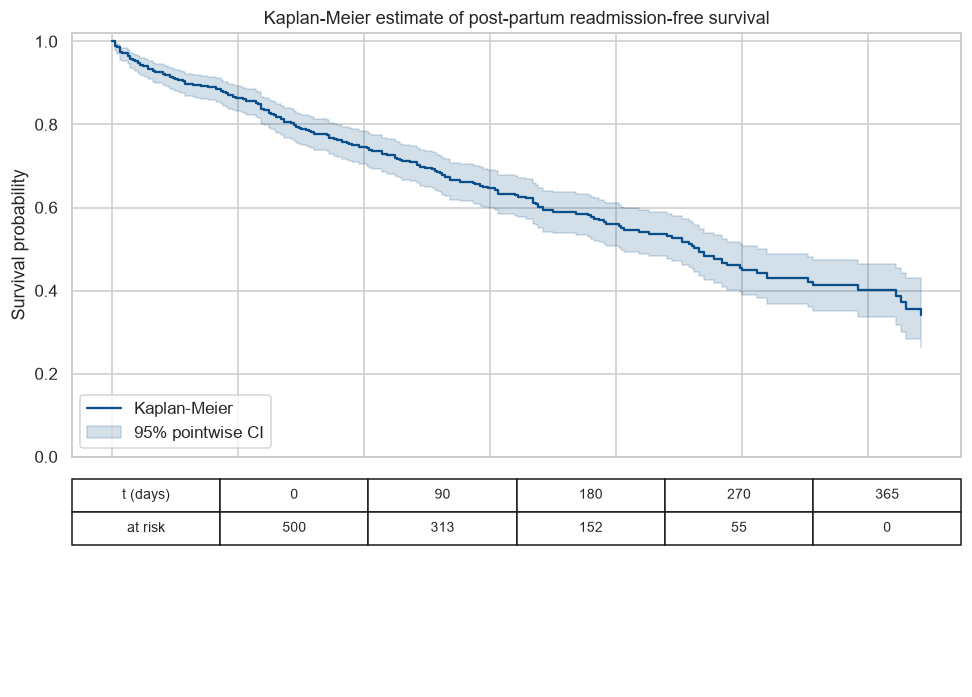

Survival at 90 days: 0.7637 (95% CI 0.7225 to 0.7996)
Survival at 180 days: 0.5894 (95% CI 0.5377 to 0.6374)
Median survival: 233.0
Number at risk at 0/90/180/270/365 days: [500, 313, 152, 55, 0]


{'survival_90': 0.7636945713896193,
 'ci_90': [0.7225135000491342, 0.7996274218041816],
 'survival_180': 0.589437429541154,
 'ci_180': [0.5376967802281104, 0.6374260529022242],
 'median_survival': 233.0,
 'median_ci': [202.0, 260.0],
 'number_at_risk': {'0': 500, '90': 313, '180': 152, '270': 55, '365': 0}}

In [33]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

km_all = SurvfuncRight(surv["time_days"], surv["readmitted"])
km_times = km_all.surv_times
km_probs = km_all.surv_prob
km_se = km_all.surv_prob_se


def km_survival_at(time_point):
    idx = int(np.searchsorted(km_times, time_point, side="right")) - 1
    return 1.0 if idx < 0 else float(km_probs[idx]), idx


def km_loglog_ci(time_point):
    probability, idx = km_survival_at(time_point)
    if idx < 0:
        return 1.0, 1.0
    se = float(km_se[idx])
    if probability <= 0 or probability >= 1:
        return probability, probability
    factor = 1.96 * se / (probability * np.log(probability))
    return (float(probability ** np.exp(-factor)),
            float(probability ** np.exp(factor)))


s90, _ = km_survival_at(90)
s180, _ = km_survival_at(180)
ci90 = km_loglog_ci(90)
ci180 = km_loglog_ci(180)
try:
    median_survival = float(km_all.quantile(0.5))
    median_ci_raw = km_all.quantile_ci(0.5)
    median_ci = [float(v) for v in median_ci_raw]
except Exception as exc:  # pragma: no cover - depends on follow-up
    median_survival = None
    median_ci = None

lower = np.array([km_loglog_ci(float(t))[0] for t in km_times])
upper = np.array([km_loglog_ci(float(t))[1] for t in km_times])
fig, (ax, risk_ax) = plt.subplots(
    2, 1, figsize=(9, 6.5), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)
ax.step(np.r_[0, km_times], np.r_[1, km_probs], where="post",
        color="#0b4f8a", label="Kaplan-Meier")
ax.fill_between(np.r_[0, km_times], np.r_[1, lower], np.r_[1, upper],
                step="post", alpha=0.18, color="#0b4f8a",
                label="95% pointwise CI")
ax.set_ylim(0, 1.02)
ax.set_ylabel("Survival probability")
ax.set_title("Kaplan-Meier estimate of post-partum readmission-free survival")
ax.legend(loc="lower left")

risk_times = [0, 90, 180, 270, 365]
at_risk = [int((surv["time_days"] >= t).sum()) for t in risk_times]
risk_ax.set_axis_off()
table = risk_ax.table(
    cellText=[["t (days)"] + [str(t) for t in risk_times],
              ["at risk"] + [str(v) for v in at_risk]],
    cellLoc="center", loc="top",
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.6)
plt.tight_layout()
plt.show()
plt.close("all")

print(f"Survival at 90 days: {s90:.4f} (95% CI {ci90[0]:.4f} to {ci90[1]:.4f})")
print(f"Survival at 180 days: {s180:.4f} (95% CI {ci180[0]:.4f} to {ci180[1]:.4f})")
print(f"Median survival: {median_survival}")
print("Number at risk at 0/90/180/270/365 days:", at_risk)
record("Q10b", {
    "survival_90": s90, "ci_90": list(ci90),
    "survival_180": s180, "ci_180": list(ci180),
    "median_survival": median_survival, "median_ci": median_ci,
    "number_at_risk": dict(zip([str(t) for t in risk_times], at_risk)),
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q10c — Compare survival curves

**Practical requirement.** Compare Kaplan-Meier curves by anaemia status and perform a log-rank test.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Compare two censored survival experiences.
- Statistical concept: The log-rank test compares observed and expected events across event times under equal survival.
- Do you need to write code? Yes — one comparison cell.
- What to do in Jupyter: Run Q10(c) and compare curve separation with the log-rank p-value.
- Code to use: Use the verified Q10(c) code cell.
- Output to inspect: Two KM curves, group medians where estimable and log-rank chi-square/p.
- Important values or observations: Curve separation and the log-rank statistic/p-value.
- How to interpret it: The test is association-only; it does not adjust for other covariates.
- What to report: Report the two group curves, any estimable group medians and the log-rank results.
- Common mistakes to avoid: Assuming crossing curves satisfy the log-rank assumptions without checking.

**Output to inspect.** Stratified KM plot and log-rank output.

**Interpretation guidance.** A small p-value suggests different readmission-free survival distributions between groups.

**Reporting guidance.** Use the log-rank template and avoid causal wording.

**Worked report from the executed notebook.** Kaplan-Meier curves differed by anaemia status (log-rank chi-square=22.57, df=1, p<0.0001); median readmission-free survival was Anaemia 169 days; No anaemia 311 days. The test compares the entire observed curve history, not only the medians.

*Verified source:* Q10c output · postpartum_survival.csv. *Teaching note:* The log-rank test is unadjusted and observational. Q10e adds covariates and Q10f checks the proportional-hazards assumption.

**Common mistakes.** Claiming anaemia caused the difference based on an unadjusted curve comparison.


**Code cell `q10c`**

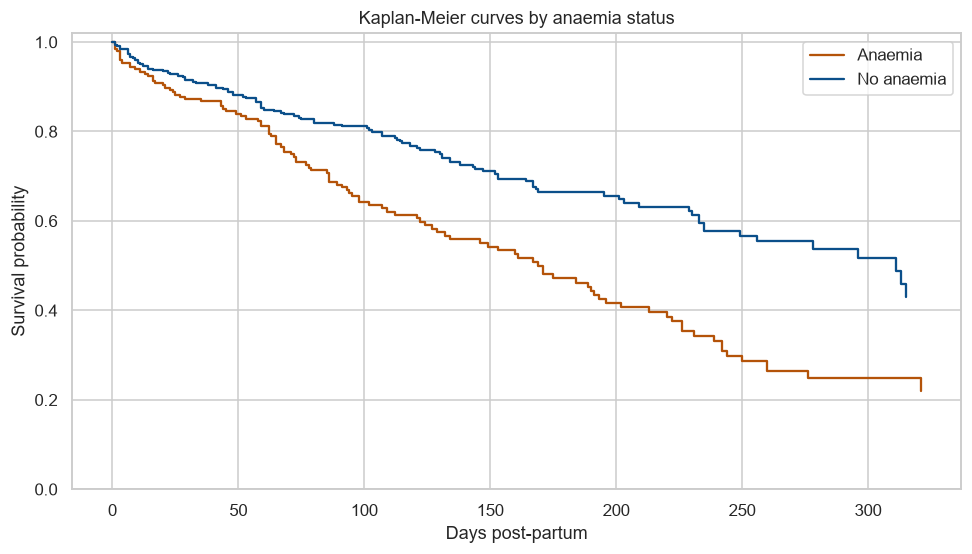

Log-rank chi-square(1) = 22.5672, p = 2.029e-06
Anaemia: n = 196, S(90) = 0.6814
No anaemia: n = 304, S(90) = 0.8155


{'logrank_chi2': 22.567150027588177,
 'logrank_p': 2.029248805613964e-06,
 'groups': ['Anaemia', 'No anaemia'],
 'median_survival': {'Anaemia': 169.0, 'No anaemia': 311.0}}

In [34]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

strata = ["Anaemia", "No anaemia"]
km_by_group = {
    group: SurvfuncRight(
        surv.loc[surv["anaemia"] == group, "time_days"],
        surv.loc[surv["anaemia"] == group, "readmitted"],
    )
    for group in strata
}

# Standard two-group log-rank test.
event_times = np.sort(surv.loc[surv["readmitted"] == 1, "time_days"].unique())
observed = expected = variance = 0.0
for time_point in event_times:
    at_risk_all = int((surv["time_days"] >= time_point).sum())
    at_risk_a = int(((surv["time_days"] >= time_point) &
                     (surv["anaemia"] == "Anaemia")).sum())
    events_all = int(((surv["time_days"] == time_point) &
                      (surv["readmitted"] == 1)).sum())
    events_a = int(((surv["time_days"] == time_point) &
                    (surv["readmitted"] == 1) &
                    (surv["anaemia"] == "Anaemia")).sum())
    proportion = at_risk_a / at_risk_all
    observed += events_a
    expected += events_all * proportion
    if at_risk_all > 1:
        variance += (events_all * proportion * (1 - proportion) *
                     (at_risk_all - events_all) / (at_risk_all - 1))
logrank_chi2 = (observed - expected) ** 2 / variance
logrank_p = float(st.chi2.sf(logrank_chi2, df=1))

fig, ax = plt.subplots(figsize=(9, 5.2))
colors = {"Anaemia": "#b45309", "No anaemia": "#0b4f8a"}
for group in strata:
    km = km_by_group[group]
    ax.step(np.r_[0, km.surv_times], np.r_[1, km.surv_prob], where="post",
            label=group, color=colors[group])
ax.set(title="Kaplan-Meier curves by anaemia status",
       xlabel="Days post-partum", ylabel="Survival probability")
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()
plt.close("all")

print(f"Log-rank chi-square(1) = {logrank_chi2:.4f}, p = {logrank_p:.4g}")
for group in strata:
    km = km_by_group[group]
    idx90 = int(np.searchsorted(km.surv_times, 90, side="right")) - 1
    n_group = int((surv["anaemia"] == group).sum())
    if idx90 >= 0:
        print(f"{group}: n = {n_group}, S(90) = {km.surv_prob[idx90]:.4f}")
    else:
        print(f"{group}: n = {n_group}, S(90) = not estimable before first event")
record("Q10c", {
    "logrank_chi2": float(logrank_chi2), "logrank_p": logrank_p,
    "groups": strata,
    "median_survival": {
        group: (float(km_by_group[group].quantile(0.5))
                if np.isfinite(km_by_group[group].quantile(0.5)) else None)
        for group in strata
    },
})


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q10d — Exponential rate

**Practical requirement.** Estimate the constant-hazard rate from events and person-time.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Estimate a readmission rate under an exponential survival model.
- Statistical concept: The exponential model assumes a constant hazard; the rate is events divided by total person-time.
- Do you need to write code? Yes — one rate calculation cell.
- What to do in Jupyter: Run Q10(a), then Q10(d), and compare S(90)/S(180) with the earlier KM values.
- Code to use: Use the verified Q10(d) code cell.
- Output to inspect: Events, person-time, rate, per-1,000 rate, exact CI and exponential S(90)/S(180).
- Important values or observations: Whether the exponential probabilities are close to the KM probabilities.
- How to interpret it: The constant-hazard assumption is strong and should be checked against the KM curve.
- What to report: Report the rate with person-time and CI, then compare with KM.
- Common mistakes to avoid: Using events/population instead of events/person-time, or ignoring the constant-hazard assumption.

**Output to inspect.** Person-time, rate, CI and exponential-versus-KM comparison.

**Interpretation guidance.** A close numerical match at selected times supports descriptive agreement, not proof of constant hazard.

**Reporting guidance.** Use the exponential-rate template with the assumption stated.

**Worked report from the executed notebook.** There were 209 readmissions over 68,841 person-days, giving a rate of 3.036 per 1,000 person-days (95% CI 2.638 to 3.477). Under the constant-hazard exponential model, S(90)=0.7609 and S(180)=0.5790; compare these with the non-parametric Kaplan-Meier estimates before relying on the model.

*Verified source:* Q10b and Q10d outputs · postpartum_survival.csv. *Teaching note:* The rate is events per person-time, not events per person. A close match at two times supports descriptive agreement but does not prove a constant hazard.

**Common mistakes.** Treating the rate as a probability or ignoring censoring.


**Code cell `q10d`**

In [35]:
_required_cells = ('q10a',)
_required_names = ('events',)
_missing = [name for name in _required_names if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run prerequisite code cell(s) " + ", ".join(_required_cells)
        + " before this cell. Missing objects: " + ", ".join(_missing)
    )

# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

total_person_time = float(surv["time_days"].sum())
rate = events / total_person_time
rate_per_1000 = rate * 1000
rate_ci = (
    float(st.chi2.ppf(0.025, 2 * events) / (2 * total_person_time)),
    float(st.chi2.ppf(0.975, 2 * events + 2) / (2 * total_person_time)),
)
exponential_s90 = float(np.exp(-rate * 90))
exponential_s180 = float(np.exp(-rate * 180))
print(f"Events = {events}")
print(f"Total person-time = {total_person_time:,.0f} person-days")
print(f"Rate = {rate:.6f} per person-day = {rate_per_1000:.3f} per 1,000 person-days")
print(f"Exact Poisson 95% CI = [{rate_ci[0]:.6f}, {rate_ci[1]:.6f}] per person-day")
print(f"Exponential model S(90) = {exponential_s90:.4f}, "
      f"S(180) = {exponential_s180:.4f}")
record("Q10d", {
    "events": events, "person_time_days": total_person_time,
    "rate_per_person_day": float(rate),
    "rate_per_1000_person_days": float(rate_per_1000),
    "ci_per_1000_person_days": [rate_ci[0] * 1000, rate_ci[1] * 1000],
    "exponential_s90": exponential_s90,
    "exponential_s180": exponential_s180,
})


Events = 209
Total person-time = 68,841 person-days
Rate = 0.003036 per person-day = 3.036 per 1,000 person-days
Exact Poisson 95% CI = [0.002638, 0.003477] per person-day
Exponential model S(90) = 0.7609, S(180) = 0.5790


{'events': 209,
 'person_time_days': 68841.0,
 'rate_per_person_day': 0.0030359814645342163,
 'rate_per_1000_person_days': 3.0359814645342165,
 'ci_per_1000_person_days': [2.6383091376616434, 3.476671597703874],
 'exponential_s90': 0.7609114166228408,
 'exponential_s180': 0.5789861839469784}

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q10e — Cox proportional hazards

**Practical requirement.** Fit readmitted ~ anaemia + delivery_mode + age and interpret adjusted hazard ratios.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Model the hazard of readmission with covariates.
- Statistical concept: A hazard ratio is a relative instantaneous event rate; an adjusted HR holds the other covariates fixed.
- Do you need to write code? Yes — one Cox model cell.
- What to do in Jupyter: Run Q10(e) and identify the reference group for each categorical term.
- Code to use: Use the verified Q10(e) code cell.
- Output to inspect: Coefficients, HRs, 95% CIs and p-values for anaemia, caesarean and age.
- Important values or observations: The adjusted HRs and whether their CIs exclude 1.
- How to interpret it: HR is not a risk ratio, and observational HRs are not causal effects.
- What to report: Report adjusted HRs with CIs/p and reference levels.
- Common mistakes to avoid: Calling HR a risk ratio or omitting reference categories.

**Output to inspect.** Cox coefficient/HR table.

**Interpretation guidance.** An HR above 1 means a higher instantaneous readmission hazard at fixed covariates.

**Reporting guidance.** Use the Cox template with explicit reference levels and non-causal wording.

**Worked report from the executed notebook.** In the Cox model, adjusted hazard ratios were anaemia HR 1.894 (95% CI 1.443 to 2.486, p<0.0001) — higher hazard at fixed covariates; caesarean HR 1.572 (95% CI 1.176 to 2.101, p=0.0022) — higher hazard at fixed covariates; age HR 1.020 (95% CI 0.998 to 1.042, p=0.0816) — no clear change in hazard at fixed covariates (analysis of 500 women and 209 events). Reference levels are anaemia = No anaemia, delivery_mode = Vaginal and age = per one-year increase. Q10f's Schoenfeld screen flags a time trend for anaemia and caesarean, so constant hazard ratios for those terms should be treated cautiously.

*Verified source:* Q10a, Q10e and Q10f outputs · postpartum_survival.csv. *Teaching note:* A hazard ratio is a relative instantaneous event rate, not a risk ratio. The age point estimate is above 1 but its interval includes 1 and p>0.05, so it is not clear evidence at the 5% level.

**Common mistakes.** Ignoring the proportional hazards assumption.


**Code cell `q10e`**

In [36]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

cox_design = pd.DataFrame({
    "anaemia": (surv["anaemia"] == "Anaemia").astype(float),
    "caesarean": (surv["delivery_mode"] == "Caesarean").astype(float),
    "age": surv["age"].astype(float),
})
cox_model = PHReg(
    endog=surv["time_days"].to_numpy(dtype=float),
    exog=cox_design.to_numpy(dtype=float),
    status=surv["readmitted"].to_numpy(dtype=int),
).fit()
cox_ci = cox_model.conf_int()
cox_terms = pd.DataFrame({
    "term": cox_design.columns,
    "coefficient": cox_model.params,
    "hazard_ratio": np.exp(cox_model.params),
    "hr_ci_low": np.exp(cox_ci[:, 0]),
    "hr_ci_high": np.exp(cox_ci[:, 1]),
    "p_value": cox_model.pvalues,
})
print(cox_terms.to_string(index=False, float_format=lambda v: f"{v:.5g}"))
print("\nReference levels: anaemia = No anaemia; delivery_mode = Vaginal; "
      "age = per one-year increase.")
record("Q10e", cox_terms.to_dict(orient="records"))


     term  coefficient  hazard_ratio  hr_ci_low  hr_ci_high    p_value
  anaemia      0.63867         1.894      1.443      2.4858 4.1608e-06
caesarean      0.45239        1.5721     1.1761      2.1014  0.0022478
      age     0.019581        1.0198    0.99755      1.0425    0.08157

Reference levels: anaemia = No anaemia; delivery_mode = Vaginal; age = per one-year increase.


[{'term': 'anaemia',
  'coefficient': 0.6386730247741905,
  'hazard_ratio': 1.8939659651453198,
  'hr_ci_low': 1.4430167660893085,
  'hr_ci_high': 2.4858388075768456,
  'p_value': 4.160840042411009e-06},
 {'term': 'caesarean',
  'coefficient': 0.4523878494130527,
  'hazard_ratio': 1.57206155350336,
  'hr_ci_low': 1.176084015848786,
  'hr_ci_high': 2.1013613778432245,
  'p_value': 0.0022477535129053717},
 {'term': 'age',
  'coefficient': 0.01958141348456775,
  'hazard_ratio': 1.0197743868674463,
  'hr_ci_low': 0.9975484670840552,
  'hr_ci_high': 1.0424955121736947,
  'p_value': 0.08157016853329652}]

**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

#### Q10f — Proportional hazards check

**Practical requirement.** Assess proportional hazards using Schoenfeld residual diagnostics.
**Task classification.** Mixed
**Code required.** Yes

**Learning guide**

- What is being asked? Check whether the Cox proportional hazards assumption is plausible.
- Statistical concept: Proportional hazards means covariate hazard ratios are constant over follow-up; Schoenfeld residuals should show no time trend.
- Do you need to write code? Yes — one diagnostic cell.
- What to do in Jupyter: Run Q10(e), then Q10(f), and look for trends in each residual plot.
- Code to use: Use the verified Q10(f) code cell.
- Output to inspect: Schoenfeld residual plots, correlations with log(time), p-values and Holm-adjusted p-values.
- Important values or observations: Any significant time trend after multiplicity adjustment.
- How to interpret it: This statsmodels-based screen is an approximate Python diagnostic, not a definitive proportional-hazards test.
- What to report: Report the diagnostic method, p-values and what a violation would imply.
- Common mistakes to avoid: Declaring PH validated solely because one plot looks flat, or ignoring a clear time trend.

**Output to inspect.** Residual plots and screening-test table.

**Interpretation guidance.** A time trend suggests the hazard ratio may change over follow-up.

**Reporting guidance.** Report the screen, its limitation and possible remedies such as time-varying effects or stratification.

**Worked report from the executed notebook.** The Schoenfeld-residual screen gave anaemia: Spearman rho=0.424, raw p<0.0001, Holm p<0.0001 (concern); caesarean: Spearman rho=0.501, raw p<0.0001, Holm p<0.0001 (concern); age: Spearman rho=-0.023, raw p=0.7358, Holm p=0.7358 (no flagged concern). A time trend remains for anaemia, caesarean after adjustment, so constant hazard ratios are questionable for those terms.

*Verified source:* Q10f output · postpartum_survival.csv. *Teaching note:* This is an approximate statsmodels screening test in Python, not a definitive proportional-hazards test. A violation suggests time-varying effects or stratification.

**Common mistakes.** Claiming the assumption is proven, or describing this Python screen as a definitive test.


**Code cell `q10f`**

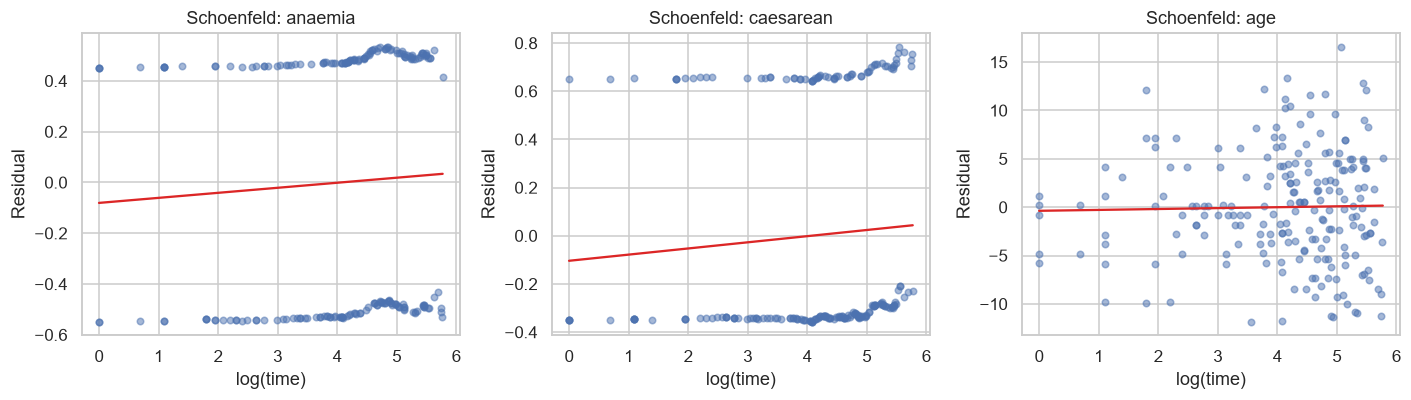

     term  spearman_rho    p_value     p_holm  flag_ph_concern
  anaemia       0.42442 1.5107e-10 3.0214e-10             True
caesarean       0.50071 1.1589e-14 3.4766e-14             True
      age     -0.023478    0.73579    0.73579            False
This is a Schoenfeld-residual screening test using statsmodels 0.15; it is an approximate Python diagnostic, not a definitive proportional-hazards test.


[{'term': 'anaemia',
  'spearman_rho': 0.4244187577868859,
  'p_value': 1.510695751078174e-10,
  'p_holm': 3.021391502156348e-10,
  'flag_ph_concern': True},
 {'term': 'caesarean',
  'spearman_rho': 0.5007106992568828,
  'p_value': 1.1588708710226389e-14,
  'p_holm': 3.4766126130679167e-14,
  'flag_ph_concern': True},
 {'term': 'age',
  'spearman_rho': -0.023477950844014106,
  'p_value': 0.7357945020654691,
  'p_holm': 0.7357945020654691,
  'flag_ph_concern': False}]

In [37]:
_required_cells = ('q10e',)
_required_names = ('cox_model', 'cox_design')
_missing = [name for name in _required_names if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run prerequisite code cell(s) " + ", ".join(_required_cells)
        + " before this cell. Missing objects: " + ", ".join(_missing)
    )

# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

schoenfeld = pd.DataFrame(
    cox_model.schoenfeld_residuals, columns=cox_design.columns
)
schoenfeld["time_days"] = surv["time_days"].to_numpy()
plot_data = schoenfeld.dropna(subset=list(cox_design.columns)).copy()
plot_data["log_time"] = np.log(plot_data["time_days"])

ph_rows = []
for term in cox_design.columns:
    rho, p_value = st.spearmanr(plot_data[term], plot_data["log_time"])
    ph_rows.append({
        "term": term,
        "spearman_rho": float(rho),
        "p_value": float(p_value),
    })
ph_tests = pd.DataFrame(ph_rows)
reject, p_holm, _, _ = multipletests(ph_tests["p_value"], method="holm")
ph_tests["p_holm"] = p_holm
ph_tests["flag_ph_concern"] = reject

fig, axes = plt.subplots(1, len(cox_design.columns), figsize=(13, 3.8))
for axis, term in zip(np.atleast_1d(axes), cox_design.columns):
    axis.scatter(plot_data["log_time"], plot_data[term], alpha=0.5, s=18)
    slope, intercept = np.polyfit(plot_data["log_time"], plot_data[term], 1)
    x_line = np.linspace(plot_data["log_time"].min(),
                         plot_data["log_time"].max(), 50)
    axis.plot(x_line, intercept + slope * x_line, color="#dc2626")
    axis.set(title=f"Schoenfeld: {term}", xlabel="log(time)", ylabel="Residual")
plt.tight_layout()
plt.show()
plt.close("all")

print(ph_tests.to_string(index=False, float_format=lambda v: f"{v:.5g}"))
print("This is a Schoenfeld-residual screening test using statsmodels 0.15; "
      "it is an approximate Python diagnostic, not a definitive proportional-hazards test.")
record("Q10f", ph_tests.to_dict(orient="records"))


**After running:** compare the actual output with the *Output to inspect* and *Interpretation guidance* above, then complete the *Reporting guidance* in your own words.

In [38]:
mark_done("Q10")

Progress: ■■■■■■■■■■  10/10 questions covered


<a id="reporting-templates"></a>
## Reporting templates

Each template keeps placeholders as a reusable writing pattern. The worked example immediately underneath fills every placeholder from the verified notebook output, so you can compare the frame with a completed, data-grounded sentence. Do not copy a result that does not match your own output.


### Descriptive statistics

**Reusable pattern**

> In the simulated teaching cohort, {variable} had n={n} non-missing observations (mean={mean}, SD={sd}, median={median}, IQR={iqr}). {n_missing} records were missing.

**Worked example from Q2b**

> Haemoglobin used 382 non-missing values (mean 11.49 g/dL, SD 1.42, median 11.50, IQR 1.97); 18 records were missing. BMI had 10 missing values, whereas birthweight used all 400 records (mean 3,046.89 g, SD 442.44).

*Verified source:* Q2b output · anc_cohort.csv. *Teaching note:* Report n beside each summary. The differing denominators explain why later anaemia analyses use fewer than the full cohort.

See the executed Q2b section above for the full output.


### Probability

**Reusable pattern**

> The sample proportion of {event} was {x}/{n} = {p:.4f}. This estimates the underlying probability but is not itself a theoretical probability.

**Worked example from Q1a**

> In the simulated ANC cohort (n=400), 47/400 (0.1175) preterm delivery and 43/400 (0.1075) low birth weight. These are observed sample proportions from the recorded outcome flags, not known population probabilities.

*Verified source:* Q1a output · anc_cohort.csv. *Teaching note:* Both outcome flags are complete for every record here. Do not switch to the smaller anaemia denominator used later.

See the executed Q1a section above for the full output.


### Correlation

**Reusable pattern**

> {x} and {y} showed {strength} {direction} association (Pearson r={r}, p={p}; Spearman rho={rho}). Because the data are observational, this is not causal.

**Worked example from Q2d**

> Gestational age and birthweight showed a positive association (Pearson r=0.365, 95% CI 0.277 to 0.447, p<0.0001; Spearman rho=0.331, p<0.0001; n=400). The rank-based estimate is close to the Pearson estimate, which is reassuring, but the scatterplot and influence diagnostics are still needed before ruling out influential points.

*Verified source:* Q2c and Q2d outputs · anc_cohort.csv. *Teaching note:* Report both coefficients and inspect the scatterplot first. An observational association is not evidence that gestational age causes birthweight.

See the executed Q2d section above for the full output.


### Confidence interval

**Reusable pattern**

> The estimated {parameter} was {estimate} with a 95% confidence interval of ({low}, {high}), computed using {method}.

**Worked example from Q3a**

> Mean birthweight was 3,046.89 g (SD 442.44, n=400, df=399); SE = SD/sqrt(n) = 22.12 g and the critical t value is 1.966. The 95% t interval was 3,003.40 to 3,090.38 g, matching the SciPy endpoints 3,003.40 to 3,090.38 g.

*Verified source:* Q3a output · anc_cohort.csv. *Teaching note:* The interval targets the population mean, not the range of individual births. A 95% procedure has long-run coverage under its assumptions.

See the executed Q3a section above for the full output.


### Independent t-test

**Reusable pattern**

> Mean {outcome} was {mean1} in {group1} (n={n1}) and {mean2} in {group2} (n={n2}). Welch's t-test gave a mean difference of {diff} (95% CI {low} to {high}), t={t}, df={df}, p={p}.

**Worked example from Q4**

> Mean birthweight was 3,125.79 g with IPTp3 Yes (n=243) and 2,924.78 g with No (n=157), a difference of 201.00 g (Yes minus No; Welch 95% CI 112.76 to 289.24; t=4.48, df=317.4, p<0.0001). Levene p=0.8128 and rank-sum p<0.0001 give context for the assumption check and sensitivity analysis.

*Verified source:* Q4 output · anc_cohort.csv. *Teaching note:* Welch's test does not assume equal variances. Report the size and precision of the difference and keep the wording observational, not causal.

See the executed Q4 section above for the full output.


### Paired t-test

**Reusable pattern**

> Among {n} paired women, mean {outcome} changed by {change} (95% CI {low} to {high}); paired t={t}, p={p}.

**Worked example from Q5**

> Among 60 paired women, mean systolic blood pressure was 112.20 mmHg at booking and 115.87 mmHg at 36 weeks. The mean within-woman change was 3.67 mmHg (95% CI 1.36 to 5.98; paired t=3.17, p=0.0024), whereas the incorrect independent test gives p=0.0848 because it ignores the id linkage.

*Verified source:* Q5 output · bp_paired.csv. *Teaching note:* Analyse the 60 paired differences, not 120 independent observations. Shapiro-Wilk and the paired-difference plot support checking the t assumption.

See the executed Q5 section above for the full output.


### ANOVA

**Reusable pattern**

> One-way ANOVA comparing {outcome} across {groups} gave F({df_between},{df_within})={F}, p={p}. Tukey-adjusted pairwise comparisons are reported with 95% CIs and adjusted p-values.

**Worked example from Q6**

> One-way ANOVA comparing haemoglobin across facility type gave F(2,379)=11.36, p<0.0001; Levene p=0.0433, Alexander-Govern A=20.57 (p<0.0001) and Kruskal-Wallis H=18.54, p<0.0001. Because Levene is significant, the equal-variance ANOVA/Tukey results are assumption-dependent; the Alexander-Govern and rank-based tests are the preferred sensitivity checks here. Tukey-adjusted pairwise differences were: Rural minus Peri-urban = -0.11 g/dL (95% CI -0.53 to 0.32, adjusted p=0.8222); Urban minus Peri-urban = 0.64 g/dL (95% CI 0.24 to 1.03, adjusted p=0.0005); Urban minus Rural = 0.75 g/dL (95% CI 0.33 to 1.16, adjusted p=0.0001).

*Verified source:* Q6 output · anc_cohort.csv. *Teaching note:* Report the heteroscedastic and rank-based results before relying on classical ANOVA/Tukey when Levene is significant. Tukey differences are written in the same direction statsmodels computes them: group2 minus group1.

See the executed Q6 section above for the full output.


### Chi-square test

**Reusable pattern**

> The association between {variable1} and {variable2} was examined in a {r}x{c} table (minimum expected count={min_expected}). Chi-square={chi2}, df={df}, p={p}.

**Worked example from Q7a**

> Among women with both variables recorded, anaemia proportions were None: 24/53 (45.28% anaemia); Primary: 67/201 (33.33% anaemia); Secondary+: 48/128 (37.50% anaemia). The chi-square test gave chi2(2)=2.69, p=0.2605, with minimum expected count 19.29; there is no clear evidence of an association in these simulated data.

*Verified source:* Q7a output · anc_cohort.csv. *Teaching note:* All expected counts exceed the usual rule-of-thumb threshold of 5. A chi-square test assesses association; it does not show that education caused anaemia.

See the executed Q7a section above for the full output.


### Proportion test

**Reusable pattern**

> The observed proportion was {x}/{n}={p_hat:.4f}. Against the null value {p0}, {test} gave p={p_value}; the 95% {ci_method} interval was ({low}, {high}).

**Worked example from Q7b**

> Against the null prevalence 0.30, the observed 139/382 = 0.3639 gave an exact binomial p=0.0073; the 95% Wilson interval was 31.72% to 41.33%, which excludes the null. 18 records with missing anaemia were excluded.

*Verified source:* Q7b output and dataset audit · anc_cohort.csv. *Teaching note:* State H0, the evaluable denominator, the exact test and the interval together. The null value is a teaching hypothesis, not a clinical guideline.

See the executed Q7b section above for the full output.


### Linear regression

**Reusable pattern**

> In the model {formula}, the adjusted coefficient for {term} was {coef} (95% CI {low} to {high}, p={p}). R-squared={r2} and adjusted R-squared={adj_r2}; n={n}.

**Worked example from Q8b**

> In the adjusted model (n=390 after excluding 10 records with missing BMI), estimated mean birthweight differences were IPTp3 Yes versus No: 177.16 g (95% CI 94.46 to 259.86, p<0.0001); per additional week of gestational age: 57.40 g (95% CI 40.77 to 74.03, p<0.0001); per unit of BMI: 12.16 g (95% CI 1.76 to 22.55, p=0.0220); per additional ANC visit: 23.62 g (95% CI 2.46 to 44.77, p=0.0287). R-squared=0.183 and adjusted R-squared=0.174.

*Verified source:* Q8b output · anc_cohort.csv. *Teaching note:* Name the reference level 'IPTp3 No' and the complete-case denominator. Coefficients are conditional associations from observational data.

See the executed Q8b section above for the full output.


### Logistic regression

**Reusable pattern**

> In the logistic model {formula}, {term} had an adjusted odds ratio of {or} (95% CI {low} to {high}, p={p}). Odds ratios are not risk ratios; the data are observational.

**Worked example from Q9**

> In the logistic model for the recorded preterm flag (n=382), adjusted odds ratios were anaemia OR 2.200 (95% CI 1.183 to 4.093, p=0.0127); each additional ANC visit OR 0.833 (95% CI 0.700 to 0.990, p=0.0385); each additional year of age OR 0.998 (95% CI 0.946 to 1.051, p=0.9274). Pseudo R-squared=0.038. At age 25 with 4 ANC visits, predicted preterm probability was 20.90% with anaemia versus 10.72% without.

*Verified source:* Q9 output · anc_cohort.csv. *Teaching note:* An odds ratio is not a risk ratio. The scenario probabilities translate the log-odds model back to the probability scale for teaching; they are not causal contrasts.

See the executed Q9 section above for the full output.


### Kaplan-Meier analysis

**Reusable pattern**

> Kaplan-Meier estimated event-free survival of {s1:.4f} at {t1} days (95% CI {l1} to {u1}) and {s2:.4f} at {t2} days (95% CI {l2} to {u2}). Median survival was {median}.

**Worked example from Q10b**

> Kaplan-Meier estimated readmission-free survival as 0.7637 at 90 days (95% CI 0.7225 to 0.7996) and 0.5894 at 180 days (95% CI 0.5377 to 0.6374). Median survival was 233 days (95% CI 202 to 260); 313 women remained at risk at day 90 and 152 at day 180.

*Verified source:* Q10b output · postpartum_survival.csv. *Teaching note:* Median observed follow-up and median survival are different quantities. Numbers at risk show where the tail of the curve is least precise.

See the executed Q10b section above for the full output.


### Log-rank test

**Reusable pattern**

> Survival curves differed by {grouping} (log-rank chi-square={chi2}, df={df}, p={p}). This unadjusted test does not establish causation.

**Worked example from Q10c**

> Kaplan-Meier curves differed by anaemia status (log-rank chi-square=22.57, df=1, p<0.0001); median readmission-free survival was Anaemia 169 days; No anaemia 311 days. The test compares the entire observed curve history, not only the medians.

*Verified source:* Q10c output · postpartum_survival.csv. *Teaching note:* The log-rank test is unadjusted and observational. Q10e adds covariates and Q10f checks the proportional-hazards assumption.

See the executed Q10c section above for the full output.


### Exponential survival rate

**Reusable pattern**

> There were {events} events over {person_time} person-days, giving a rate of {rate:.6f} per person-day ({rate1000:.2f} per 1,000 person-days; 95% CI {low} to {high}). This assumes a constant hazard.

**Worked example from Q10d**

> There were 209 readmissions over 68,841 person-days, giving a rate of 3.036 per 1,000 person-days (95% CI 2.638 to 3.477). Under the constant-hazard exponential model, S(90)=0.7609 and S(180)=0.5790; compare these with the non-parametric Kaplan-Meier estimates before relying on the model.

*Verified source:* Q10b and Q10d outputs · postpartum_survival.csv. *Teaching note:* The rate is events per person-time, not events per person. A close match at two times supports descriptive agreement but does not prove a constant hazard.

See the executed Q10d section above for the full output.


### Cox regression

**Reusable pattern**

> In the Cox model {formula}, {term} had an adjusted hazard ratio of {hr} (95% CI {low} to {high}, p={p}). A hazard ratio is not a risk ratio.

**Worked example from Q10e**

> In the Cox model, adjusted hazard ratios were anaemia HR 1.894 (95% CI 1.443 to 2.486, p<0.0001) — higher hazard at fixed covariates; caesarean HR 1.572 (95% CI 1.176 to 2.101, p=0.0022) — higher hazard at fixed covariates; age HR 1.020 (95% CI 0.998 to 1.042, p=0.0816) — no clear change in hazard at fixed covariates (analysis of 500 women and 209 events). Reference levels are anaemia = No anaemia, delivery_mode = Vaginal and age = per one-year increase. Q10f's Schoenfeld screen flags a time trend for anaemia and caesarean, so constant hazard ratios for those terms should be treated cautiously.

*Verified source:* Q10a, Q10e and Q10f outputs · postpartum_survival.csv. *Teaching note:* A hazard ratio is a relative instantaneous event rate, not a risk ratio. The age point estimate is above 1 but its interval includes 1 and p>0.05, so it is not clear evidence at the 5% level.

See the executed Q10e section above for the full output.


<a id="limitations"></a>
## Limitations

- The datasets are fixed-seed simulated teaching data, not real patient records.
- The supplied `preterm` flag disagrees with a literal decimal `gest_age < 37` rule for nine records; the recorded flag is used as primary.
- `lifelines` is not installed, so survival analysis uses statsmodels and a transparent log-rank implementation. The proportional-hazards check is an approximate Python Schoenfeld-residual screen, not a definitive proportional-hazards test.
- Statistical associations from these observational data are not causal effects.
- No biomedical threshold, guideline or population claim is inferred from these simulated data.


## Machine-readable verification record

In [39]:
# Prerequisite: run the "Reusable setup" cell once in this kernel.
try:
    anc
    record
except NameError as exc:
    raise RuntimeError(
        "Run the 'Reusable setup' cell before this cell. It creates "
        "anc, bp, surv, RESULTS and record(); this question cell reuses them."
    ) from exc

print("MNH_VERIFIED_RESULTS_JSON:" +
      json.dumps(RESULTS, ensure_ascii=False, sort_keys=True, allow_nan=False))


MNH_VERIFIED_RESULTS_JSON:{"Audit": {"anaemia_mismatches": 0, "datasets": [{"columns": 14, "dataset": "anc_cohort.csv", "duplicate_rows": 0, "missing_cells": 46, "rows": 400, "sha256": "EE9D58D5E484D62244B62E17910AEDE241B074B4E7F70D22C783F50DD6E9E1DA"}, {"columns": 3, "dataset": "bp_paired.csv", "duplicate_rows": 0, "missing_cells": 0, "rows": 60, "sha256": "677B7643994C0C57CE9FA2C052EEB22086D5B20537E5D8FE1290A98B3AFEF786"}, {"columns": 6, "dataset": "postpartum_survival.csv", "duplicate_rows": 0, "missing_cells": 0, "rows": 500, "sha256": "0099FFCFCC226141DD762E6ABD338343325DC360A8011FFC571CAB06AC332EF2"}], "education_levels": {"None": 55, "Primary": 212, "Secondary+": 133}, "facility_levels": {"Peri-urban": 133, "Rural": 113, "Urban": 154}, "iptp3_levels": {"No": 157, "Yes": 243}, "lowbw_mismatches": 0, "preterm_mismatches": 9}, "Q10a": {"censored": 291, "censoring_proportion": 0.582, "events": 209, "median_observed_follow_up": 119.0, "participants": 500}, "Q10b": {"ci_180": [0.53769